In [1]:
# Setup and helper functions moved to external module
from equations_file import *

# If you change the external module and want live reload during development, uncomment:
# %load_ext autoreload
# %autoreload 2

/Users/simoncorrera/Desktop/MQ NGC3201 project copy/Jupyter Notebooks/equations_file.py:676: SyntaxWarning: invalid escape sequence '\%'
  elm_frequency_table.loc[len(elm_frequency_table)] = {'Element': elm_label, f'{name}': f' & {100*count/n:.1f}\%'}


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.

Due to maintenance reasons, the archive won't be available on 12 November at 16:00 CET for 1 hour approximately. Apologies for the inconveniences.


In [2]:
save_dir = "/Users/simoncorrera/Desktop/MQ NGC3201 project copy/S&PinHobart_plots"

In [3]:
with fitsio.FITS(galah_Gaia_fits) as hdul1:
    data_1 = hdul1[1].read()
galah_Gaia_raw = pd.DataFrame(data_1)
galah_Gaia_raw = ensure_native_endian(galah_Gaia_raw)

In [138]:
GSE_vs_Halo_energy_test_file = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/GSE_P_Halo_elmlist_18_energy_test.csv'
GSE_vs_Halo_energy_test = pd.read_csv(GSE_vs_Halo_energy_test_file)

Seq_lim_vs_GSE_energy_test = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/Seq_con_GSE_elmlist_18_energy_test.csv'
Seq_lim_vs_GSE_energy_test = pd.read_csv(Seq_lim_vs_GSE_energy_test)

Seq_Tham_vs_GSE_energy_test = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/Seq_Tham_GSE_elmlist_18_energy_test.csv'
Seq_Tham_vs_GSE_energy_test = pd.read_csv(Seq_Tham_vs_GSE_energy_test)

Seq_lim_vs_Halo_energy_test = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/Seq_con_P_Halo_elmlist_18_energy_test.csv'
Seq_lim_vs_Halo_energy_test = pd.read_csv(Seq_lim_vs_Halo_energy_test)

Seq_Tham_vs_Halo_energy_test = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/Seq_Tham_P_Halo_elmlist_18_energy_test.csv'
Seq_Tham_vs_Halo_energy_test = pd.read_csv(Seq_Tham_vs_Halo_energy_test)

Seq_lim_vs_Seq_Tham_energy_test = '/Users/simoncorrera/Desktop/MQ NGC3201 project copy/sequoia paper matieral/Energy_Test_results/Seq_con_Seq_Tham_elmlist_18_energy_test.csv'
Seq_lim_vs_Seq_Tham_energy_test = pd.read_csv(Seq_lim_vs_Seq_Tham_energy_test)


In [139]:
galah_Gaia = galah_Gaia_raw[(galah_Gaia_raw['snr_px_ccd3'] > 30)       # Kushniruk 2026 also has cuts in log g and temp. I wonder if I should as well
                        & (galah_Gaia_raw['flag_sp'] == 0)
                        & (galah_Gaia_raw['flag_fe_h'] == 0)
                        & (galah_Gaia_raw['e_fe_h'] < 0.1)
                        & (galah_Gaia_raw['flag_sp_fit'] == 0)
                        & (galah_Gaia_raw['flag_red'] == 0)
                        & (galah_Gaia_raw['ruwe'] < 1.4)
                        & (galah_Gaia_raw['logg'] < 3.5)
                        & (galah_Gaia_raw['teff'] > 4000)
                        & (galah_Gaia_raw['teff'] < 6500)
                        # & (galah_Gaia_raw['flag_mg_fe'] == 0)
                        # & (galah_Gaia_raw['flag_na_fe'] == 0)
                        # & (galah_Gaia_raw['flag_cu_fe'] == 0)
                        & (galah_Gaia_raw['fe_h'] < -0.8)
                        # & (galah_Gaia_raw['fe_h'] < -1.24)  # the 16th and 84th percentile spreads of all flagged elements sequoia Fe/H: -1.24, -1.72
                        # & (galah_Gaia_raw['fe_h'] > -1.72) # the 16th and 84th percentile spreads of only Fe/h flagged elements sequoia Fe/H: -1.28, -2.01
                        # & (galah_Gaia_raw['ti_fe'] > 0.25)
                        
                        & (galah_Gaia_raw['survey_name'].isin(['galah_faint', 'galah_bright', 'galah_main',
                                                               'k2_hermes', 'galah_phase2', 'tess_hermes'
                                                               ]))
                        & (galah_Gaia_raw['radial_velocity'].notnull())
                        & (galah_Gaia_raw['ra_gaia'].notnull())
                        & (galah_Gaia_raw['dec_gaia'].notnull())
                        & (galah_Gaia_raw['pmra_gaia'].notnull())
                        & (galah_Gaia_raw['pmdec_gaia'].notnull())
                        & (galah_Gaia_raw['parallax_gaia'] > 0)
                        
    ]

print(f"Number of stars after cuts: {len(galah_Gaia)}")

Number of stars after cuts: 8955


In [140]:
NGC3201_galah = pd.merge( galah_Gaia, Vmans_NGC3201_high_prob, left_on = 'gaiadr3_source_id', right_on = 'source_id', how = 'inner')
NGC5139_galah = pd.merge( galah_Gaia, Vmans_NGC5139_high_prob, left_on = 'gaiadr3_source_id', right_on = 'source_id', how = 'inner')
NGC1851_galah = pd.merge( galah_Gaia, Vmans_NGC1851_high_prob, left_on = 'gaiadr3_source_id', right_on = 'source_id', how = 'inner')   
NGC0104_galah = pd.merge( galah_Gaia, Vmans_NGC0104_high_prob, left_on = 'gaiadr3_source_id', right_on = 'source_id', how = 'inner')

galah_Kushniruk_GSE = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])-35)**2) / (17.5**2)) + (((galah_Gaia['jphi'] + 130)**2) / (250**2)) < 1)
                                #  & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                                 & (galah_Gaia_raw['flag_mg_fe'] == 0)
                                 & (galah_Gaia_raw['flag_na_fe'] == 0)
                                 & (galah_Gaia_raw['flag_cu_fe'] == 0)
                                 & ((galah_Gaia_raw['mg_fe'] - galah_Gaia_raw['cu_fe']) - ((1.06923) * galah_Gaia_raw['na_fe']) > 0.40150)
                                 ]

# Kushniruk et al . 2026 https://doi.org/10.1051/0004-6361/202451201
galah_Kushniruk_Thamnos1 = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])- 13.5)**2) / (4.0**2)) + (((galah_Gaia['jphi'] + 600)**2) / (350**2)) < 1)
                                        # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                                        # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                                        # & (galah_Gaia['survey_name'].isin(['galah_faint', 'galah_bright', 'galah_main']))
                                        & (galah_Gaia_raw['fe_h'] < -0.8)
                                      ]

galah_Kushniruk_Thamnos2 = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])-8.6)**2) / (3.5**2)) + (((galah_Gaia['jphi'] + 1184)**2) / (175**2)) < 1)
                                        # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                                        # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                                        # & (galah_Gaia['survey_name'].isin(['galah_faint', 'galah_bright', 'galah_main']))
                                        & (galah_Gaia_raw['fe_h'] < -0.8)
                                      ]

# Feuillet et al. 2021 https://doi.org/10.1093/mnras/stab2614
galah_Gaia_GSE = galah_Gaia[GSE_cuts_Diane_2021(galah_Gaia)
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id']))
                            & (galah_Gaia_raw['fe_h'] < -0.8)
                            ]

# Feuillet et al. 2021 https://doi.org/10.1093/mnras/stab2614
galah_Gaia_Sequoia = galah_Gaia[Sequoia_cuts_Diane_2021(galah_Gaia)
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id']))
                            & (galah_Gaia_raw['fe_h'] < -0.8)
                            # & (galah_Gaia_raw['fe_h'] > -1.3)

                            # & (galah_Gaia_raw['ca_fe'] < 0.37)
]

# Feuillet et al. 2021 https://doi.org/10.1093/mnras/stab2614
galah_Gaia_Sequoia_p_thamnos = galah_Gaia[Sequoia_cuts_Diane_2021(galah_Gaia)
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id']))
                            & (galah_Gaia_raw['fe_h'] < -0.8)
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_Sequoia['gaiadr3_source_id']))

                            # & (galah_Gaia_raw['y_fe'] < 0.8)
]

galah_Gaia_Halo = galah_Gaia[(np.sqrt((galah_Gaia['vphi']-230)**2 + (galah_Gaia['vr'])**2 + (galah_Gaia['vz'])**2) > 230) # Koppelman et al. 2019  https://doi.org/10.1051/0004-6361/201936738
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id'])) 
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_GSE['gaiadr3_source_id']))
                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_Sequoia['gaiadr3_source_id'])) 
                            # & (galah_Gaia_raw['fe_h'] < -1.1)
                            # & (galah_Gaia_raw['fe_h'] > -1.9)
                            & (galah_Gaia_raw['fe_h'] < -0.8)
                             ]


/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2350809491.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  galah_Kushniruk_GSE = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])-35)**2) / (17.5**2)) + (((galah_Gaia['jphi'] + 130)**2) / (250**2)) < 1)

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2350809491.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  galah_Kushniruk_Thamnos1 = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])- 13.5)**2) / (4.0**2)) + (((galah_Gaia['jphi'] + 600)**2) / (350**2)) < 1)

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2350809491.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  galah_Kushniruk_Thamnos2 = galah_Gaia[((((np.sqrt(galah_Gaia['jr'])-8.6)**2) / (3.5**2)) + (((galah_Gaia['jphi'] + 1184)**2) / (175**2)) < 1)

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2350809491.py:30: UserWarning

In [141]:
Halo_Pradosh_galah_Gaia = galah_Gaia[
                                            (galah_Gaia['fe_h'] < -0.8)&
                                            (galah_Gaia['ti_fe'] > 0.25)
                                            & (galah_Gaia['flag_ti_fe'] == 0)
                                            & (galah_Gaia['Lz'] > -1500)
                                            & (galah_Gaia['Lz'] < 1500)
                                            & (galah_Gaia['ecc_gaia'] > 0.5)
                                            & (galah_Gaia['ecc_gaia'] < 0.8)
                                            # & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_GSE['gaiadr3_source_id']))
                                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_Sequoia['gaiadr3_source_id']))
                                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                                            & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id']))
                                            # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_NGC3201_new_ratios['gaiadr3_source_id']))
                                            # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_NGC5139_new_ratios['gaiadr3_source_id']))
                                            ]

thickdisk_galah_Gaia = galah_Gaia[(galah_Gaia['fe_h'] < -0.8)
                                                 & (galah_Gaia['ti_fe'] > 0.25)
                                                 & (galah_Gaia['Lz'] > 0)
                                                 & (galah_Gaia['ecc_gaia'] < 0.5)
                                                #  & (~galah_Gaia['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                                                & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_GSE['gaiadr3_source_id']))
                                                & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_Sequoia['gaiadr3_source_id']))
                                                & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                                                & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id']))
                                                # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_NGC3201_new_ratios['gaiadr3_source_id']))
                                                # & (~galah_Gaia['gaiadr3_source_id'].isin(galah_Gaia_NGC5139_new_ratios['gaiadr3_source_id']))
                                            ]
print(len(Halo_Pradosh_galah_Gaia))
print(len(thickdisk_galah_Gaia))

galah_Gaia_Halo = Halo_Pradosh_galah_Gaia

1797
2631


In [142]:
"""Remember that the Pradosh Halo Is writen to override the other characterization for the Halo. I did this
because it was easier to do than to rewrite code for the Pradosh Halo, but I need to call it out if I want to ever use the other one"""

'Remember that the Pradosh Halo Is writen to override the other characterization for the Halo. I did this\nbecause it was easier to do than to rewrite code for the Pradosh Halo, but I need to call it out if I want to ever use the other one'

In [143]:
galah_Gaia_else = galah_Gaia_raw[(galah_Gaia_raw['snr_px_ccd3'] > 30)       # Kushniruk 2026 also has cuts in log g and temp. I wonder if I should as well
                        & (galah_Gaia_raw['flag_sp'] == 0)
                        & (galah_Gaia_raw['flag_fe_h'] == 0)
                        & (galah_Gaia_raw['e_fe_h'] < 0.1)
                        & (galah_Gaia_raw['flag_sp_fit'] == 0)
                        & (galah_Gaia_raw['flag_red'] == 0)
                        & (galah_Gaia_raw['ruwe'] < 1.4)
                        & (galah_Gaia_raw['logg'] < 3.5)
                        & (galah_Gaia_raw['teff'] > 4000)
                        & (galah_Gaia_raw['teff'] < 6500)
                        # & (galah_Gaia_raw['fe_h'] < -0.75)
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(NGC3201_galah['gaiadr3_source_id']))
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(NGC5139_galah['gaiadr3_source_id']))
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos1['gaiadr3_source_id']))
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(galah_Kushniruk_Thamnos2['gaiadr3_source_id'])) 
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(galah_Gaia_GSE['gaiadr3_source_id']))
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(galah_Gaia_Sequoia['gaiadr3_source_id'])) 
                        # & (~galah_Gaia_raw['gaiadr3_source_id'].isin(galah_Gaia_Halo['gaiadr3_source_id']))
                        # & (galah_Gaia_raw['survey_name'].isin(['galah_faint', 'galah_bright', 'galah_main',
                        #                                        'k2_hermes', 'galah_phase2', 'tess_hermes']))
                        ]

In [144]:
# print(f'len(NGC3201_galah): {len(NGC3201_galah)}')
# print(f'len(NGC5139_galah): {len(NGC5139_galah)}')
# print(f'len(NGC1851_galah): {len(NGC1851_galah)}')
# print(f'len(NGC0104_galah): {len(NGC0104_galah)}')
# print(f'len(galah_Kushniruk_GSE): {len(galah_Kushniruk_GSE)}')
print(f'len(galah_Kushniruk_Thamnos1): {len(galah_Kushniruk_Thamnos1)}')
print(f'len(galah_Kushniruk_Thamnos2): {len(galah_Kushniruk_Thamnos2)}')
print(f'len(galah_Gaia_GSE): {len(galah_Gaia_GSE)}')
print(f'len(galah_Gaia_Sequoia): {len(galah_Gaia_Sequoia)}')
print(f'len(galah_Gaia_Sequoia_p_thamnos): {len(galah_Gaia_Sequoia_p_thamnos)}')
print(f'len(galah_Gaia_Halo): {len(galah_Gaia_Halo)}')
print(f'len(galah_Gaia_else): {len(galah_Gaia_else)}')
print(f'galah_Gaia_new_ratios: {len(galah_Gaia)}')

len(galah_Kushniruk_Thamnos1): 202
len(galah_Kushniruk_Thamnos2): 19
len(galah_Gaia_GSE): 836
len(galah_Gaia_Sequoia): 118
len(galah_Gaia_Sequoia_p_thamnos): 207
len(galah_Gaia_Halo): 1797
len(galah_Gaia_else): 166969
galah_Gaia_new_ratios: 8955


/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/1007985506.py:33: UserWarning: Legend does not support handles for QuadMesh instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = plt.gca().get_legend_handles_labels()



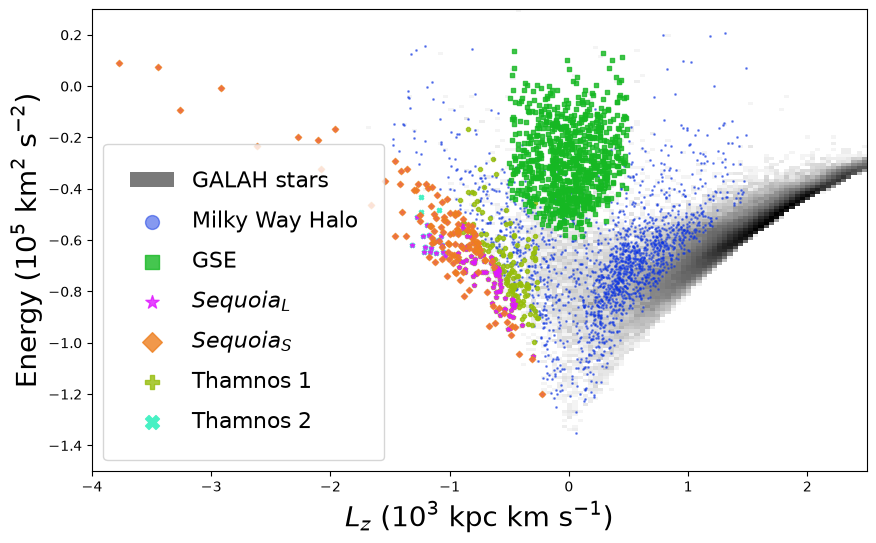

In [145]:
plt.figure(figsize=(10,6))

fontsize = 30
labelsize = 20

x_range = (-4000/1e3, 2500/1e3)
y_range = (-150000/1e5,30000/1e5)
plt.xlim(x_range)
plt.ylim(y_range)

galah_Gaia_else_plot = galah_Gaia_else[['jphi', 'energy']].dropna()
plt.hist2d(galah_Gaia_else_plot['jphi']/1e3, galah_Gaia_else_plot['energy']/1e5, bins=(150), range = (x_range, y_range), cmap=galah_Gaia_else_cmap, norm=LogNorm(),label='All GALAH stars')

plt.scatter(galah_Gaia_Halo['jphi']/1e3, galah_Gaia_Halo['energy']/1e5, label = 'Milky Way Halo', s = 1, alpha = 0.5, c = Halo_C, marker = Halo_shape)
plt.scatter(galah_Kushniruk_Thamnos1['jphi']/1e3, galah_Kushniruk_Thamnos1['energy']/1e5, label = 'Thamnos 1', s = 10, alpha = 0.8, c = thamnos_1_C, marker = thamnos_1_shape)
plt.scatter(galah_Kushniruk_Thamnos2['jphi']/1e3, galah_Kushniruk_Thamnos2['energy']/1e5, label = 'Thamnos 2', s = 10, alpha = 1.0, c = thamnos_2_C, marker = thamnos_2_shape)
plt.scatter(galah_Gaia_GSE['jphi']/1e3, galah_Gaia_GSE['energy']/1e5, label = 'GSE', s = 7, alpha = 0.8, c = GSE_C, marker = GSE_shape)
plt.scatter(galah_Gaia_Sequoia_p_thamnos['jphi']/1e3, galah_Gaia_Sequoia_p_thamnos['energy']/1e5, label = r'$Sequoia_L$', s = 10, alpha = 0.8, c = Sequoia_C_2, marker = Sequoia_shape_2)
plt.scatter(galah_Gaia_Sequoia['jphi']/1e3, galah_Gaia_Sequoia['energy']/1e5, label = r'$Sequoia_S$', s = 10, alpha = 0.8, c = Sequoia_C, marker = Sequoia_shape)

# plt.scatter(NGC1851_galah['jphi'], NGC1851_galah['energy'], label = "galah_NGC1851",  s = 10, alpha = 0.5, c = 'b')
# plt.scatter(NGC0104_galah['jphi'], NGC0104_galah['energy'], label = "NGC0104",  s = 10, alpha = 0.5, c = 'pink')

# leg = plt.legend(fontsize=15, labelspacing=0.8, borderpad=1.2)
# handles, labels = plt.get_legend_handles_labels()

# Desired legend order
galah_handle = Patch(
    facecolor=plt.get_cmap(galah_Gaia_else_cmap)(0.6),
    edgecolor='none',
    label='GALAH stars'
)
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(galah_handle)
labels.append('GALAH stars')
order = [
    labels.index('GALAH stars'),
    labels.index('Milky Way Halo'),
    labels.index('GSE'),
    labels.index(r'$Sequoia_L$'),
    labels.index(r'$Sequoia_S$'),
    labels.index('Thamnos 1'),
    labels.index('Thamnos 2')
]

leg = plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    fontsize=16,
    labelspacing=0.8,
    borderpad=1.2
)

for handle in leg.legend_handles:
    try:
        handle.set_sizes([100])
    except Exception:
        pass   

plt.xlabel(r'$L_z$ ($10^3$ kpc km s$^{-1}$)', fontsize = 20)
plt.ylabel(r'Energy ($10^5$ km$^2$ s$^{-2}$)', fontsize = 20)
# plt.title('Galah' , fontsize = 20)

filename = "energy_vs_angular_momentum.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2979041978.py:61: UserWarning: Legend does not support handles for QuadMesh instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = plt.gca().get_legend_handles_labels()



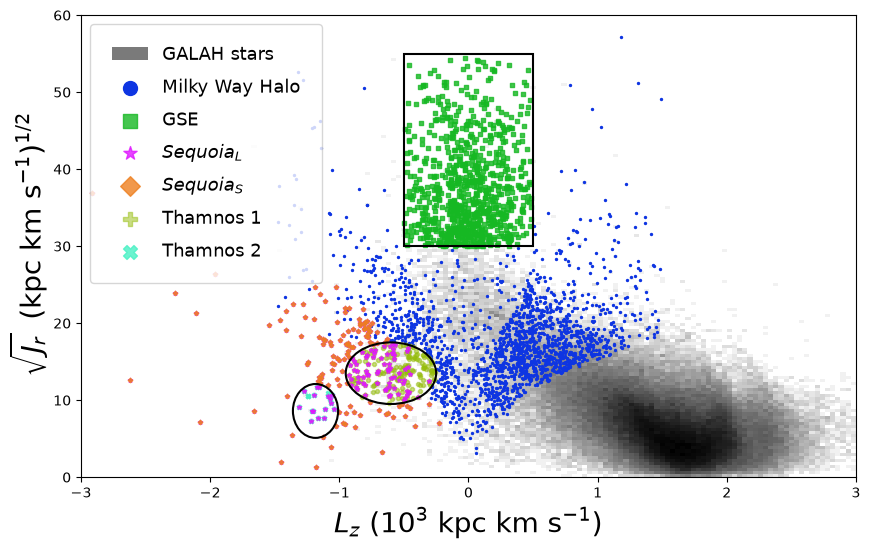

In [146]:
plt.figure(figsize=(10,6))
fontsize = 30
labelsize = 20

x_range = (-3000/1e3, 3000/1e3)
y_range = (0, 60)
plt.xlim(x_range)
plt.ylim(y_range)

# ax[0,1].scatter(galah_Gaia_else['jphi']/1e3, np.sqrt(galah_Gaia_else['jr']), label = 'Galah stars', s = 0.2, alpha = 0.3, c = galah_Gaia_else_C, marker = galah_Gaia_else_shape)
galah_Gaia_else_plot = galah_Gaia_else[['jphi', 'jr']].dropna()
plt.hist2d(galah_Gaia_else_plot['jphi']/1e3, np.sqrt(galah_Gaia_else_plot['jr']), label = 'Galah stars', bins=(150), range = (x_range, y_range), cmap=galah_Gaia_else_cmap, norm=LogNorm())

plt.scatter(galah_Gaia_Halo['jphi']/1e3, np.sqrt(galah_Gaia_Halo['jr']), label = 'Milky Way Halo', s = 2, alpha = 1.0, c = Halo_C, marker = Halo_shape)
plt.scatter(galah_Kushniruk_Thamnos1['jphi']/1e3, np.sqrt(galah_Kushniruk_Thamnos1['jr']), label = 'Thamnos 1', s = 5, alpha = 0.5, c = thamnos_1_C, marker = thamnos_1_shape)
plt.scatter(galah_Kushniruk_Thamnos2['jphi']/1e3, np.sqrt(galah_Kushniruk_Thamnos2['jr']), label = 'Thamnos 2', s = 10, alpha = 0.8, c = thamnos_2_C, marker = thamnos_2_shape)
plt.scatter(galah_Gaia_Sequoia_p_thamnos['jphi']/1e3, np.sqrt(galah_Gaia_Sequoia_p_thamnos['jr']), label = r'$Sequoia_L$', s = 10, alpha = 0.8, c = Sequoia_C_2, marker = Sequoia_shape_2)
plt.scatter(galah_Gaia_GSE['jphi']/1e3, np.sqrt(galah_Gaia_GSE['jr']), label = 'GSE', s = 5, alpha = 0.8, c = GSE_C, marker = GSE_shape)
plt.scatter(galah_Gaia_Sequoia['jphi']/1e3, np.sqrt(galah_Gaia_Sequoia['jr']), label = r'$Sequoia_S$', s = 5, alpha = 0.8, c = Sequoia_C, marker = Sequoia_shape)
plt.scatter(NGC1851_galah['jphi']/1e3, np.sqrt(NGC1851_galah['jr']), label = 'NGC 1851', s = 50, alpha = 1.0, c = 'r', marker = 'o')




GSE_pathch_corner = (-500/1e3,30)
width = 500.0/1e3 - -500.0/1e3
height = 55.0-30.0
rect = patches.Rectangle(GSE_pathch_corner, width, height,
                           linewidth=1.5,
                           edgecolor='black',
                           facecolor='none',
                           alpha=1.0)       # transparency
ax = plt.gca()
ax.add_patch(rect)

Thamnos1_patch_center = (-600/1e3,13.5)
semi_major_axis = 350.0/1e3
semi_minor_axis = 4.0
ellipse = patches.Ellipse(Thamnos1_patch_center, 2*semi_major_axis, 2*semi_minor_axis,
                           linewidth=1.5,
                           edgecolor='black',
                           facecolor='none',
                           alpha=1.0)
ax.add_patch(ellipse)

Thamnos2_patch_center = (-1184/1e3,8.6)
semi_major_axis = 175.0/1e3
semi_minor_axis = 3.5
ellipse = patches.Ellipse(Thamnos2_patch_center, 2*semi_major_axis, 2*semi_minor_axis,
                           linewidth=1.5,
                           edgecolor='black',
                           facecolor='none',
                           alpha=1.0)
ax.add_patch(ellipse)

galah_handle = Patch(
    facecolor=plt.get_cmap(galah_Gaia_else_cmap)(0.6),
    edgecolor='none',
    label='GALAH stars'
)
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(galah_handle)
labels.append('GALAH stars')
order = [
    labels.index('GALAH stars'),
    labels.index('Milky Way Halo'),
    labels.index('GSE'),
    labels.index(r'$Sequoia_L$'),
    labels.index(r'$Sequoia_S$'),
    labels.index('Thamnos 1'),
    labels.index('Thamnos 2')
]

leg = plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    fontsize=13,
    labelspacing=0.8,
    borderpad=1.2
)

for handle in leg.legend_handles:
    try:
        handle.set_sizes([100])
    except Exception:
        pass
    

plt.xlabel(r'$L_z$ ($10^3$ kpc km s$^{-1}$)', fontsize = 20)
plt.ylabel(r'$\,\sqrt{J_r}\,$ (kpc km s$^{-1}$)$^{1/2}$', fontsize = 20);

filename = "radial_action_vs_angular_momentum.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/3259241480.py:27: UserWarning: Legend does not support handles for QuadMesh instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = plt.gca().get_legend_handles_labels()



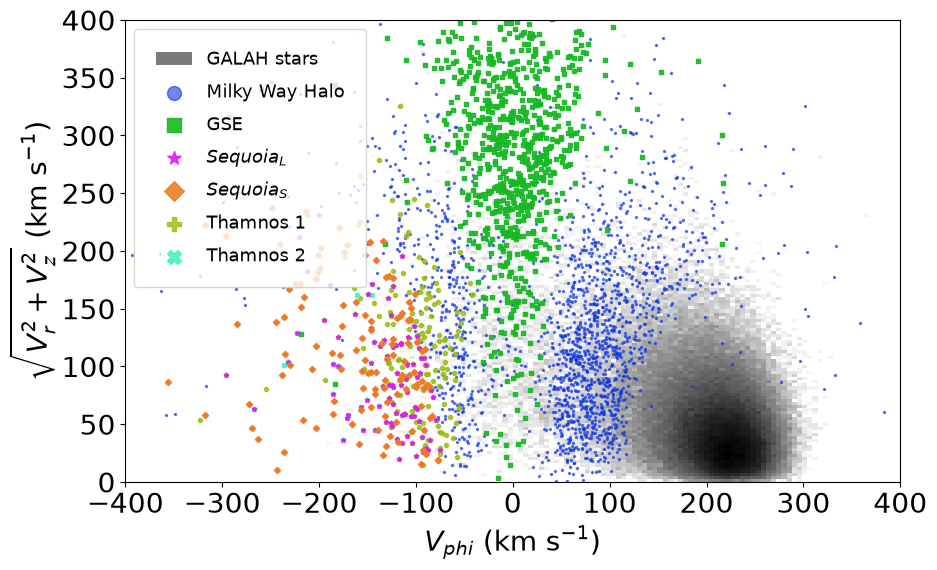

In [147]:
plt.figure(figsize=(10,6))

x_range = (-400, 400)
y_range = (0, 400)
plt.xlim(x_range)
plt.ylim(y_range)

# ax[1,1].scatter(galah_Gaia_else['vphi'], np.sqrt((galah_Gaia_else['vr'])**2 + (galah_Gaia_else['vz'])**2), label = 'All Galah stars', s = 0.2, alpha = 0.3, c = galah_Gaia_else_C, marker = galah_Gaia_else_shape)
galah_Gaia_else_plot = galah_Gaia_else[['vphi', 'vr', 'vz']].dropna()
plt.hist2d(galah_Gaia_else_plot['vphi'], np.sqrt((galah_Gaia_else_plot['vr'])**2 + (galah_Gaia_else_plot['vz'])**2), label = 'All Galah stars', bins=(150), range = (x_range, y_range), cmap=galah_Gaia_else_cmap, norm=LogNorm())

plt.scatter(galah_Gaia_Halo['vphi'], np.sqrt((galah_Gaia_Halo['vr'])**2 + (galah_Gaia_Halo['vz'])**2), label = 'Milky Way Halo', s = 2, alpha = 0.6, c = Halo_C, marker = Halo_shape)
plt.scatter(galah_Kushniruk_Thamnos1['vphi'], np.sqrt((galah_Kushniruk_Thamnos1['vr'])**2 + (galah_Kushniruk_Thamnos1['vz'])**2), label = 'Thamnos 1', s = 5, alpha = 0.8, c = thamnos_1_C, marker = thamnos_1_shape)
plt.scatter(galah_Kushniruk_Thamnos2['vphi'], np.sqrt((galah_Kushniruk_Thamnos2['vr'])**2 + (galah_Kushniruk_Thamnos2['vz'])**2), label = 'Thamnos 2', s = 10, alpha = 0.9, c = thamnos_2_C, marker = thamnos_2_shape)
plt.scatter(galah_Gaia_GSE['vphi'], np.sqrt((galah_Gaia_GSE['vr'])**2 + (galah_Gaia_GSE['vz'])**2), label = 'GSE', s = 10, alpha = 0.9, c = GSE_C, marker = GSE_shape)
plt.scatter(galah_Gaia_Sequoia_p_thamnos['vphi'], np.sqrt((galah_Gaia_Sequoia_p_thamnos['vr'])**2 + (galah_Gaia_Sequoia_p_thamnos['vz'])**2), label = r'$Sequoia_L$', s = 10, alpha = 0.9, c = Sequoia_C_2, marker = Sequoia_shape_2)
plt.scatter(galah_Gaia_Sequoia['vphi'], np.sqrt((galah_Gaia_Sequoia['vr'])**2 + (galah_Gaia_Sequoia['vz'])**2), label = r'$Sequoia_S$', s = 10, alpha = 0.9, c = Sequoia_C, marker = Sequoia_shape)
# plt.scatter(NGC1851_galah['vphi'], np.sqrt((NGC1851_galah['vr'])**2 + (NGC1851_galah['vz'])**2), label = 'NGC 1851', s = 50, alpha = 0.9, c = 'r', marker = 'o')
plt.tick_params(axis='x', labelsize = labelsize)
plt.tick_params(axis='y', labelsize = labelsize)

galah_handle = Patch(
    facecolor=plt.get_cmap(galah_Gaia_else_cmap)(0.6),
    edgecolor='none',
    label='GALAH stars'
)
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(galah_handle)
labels.append('GALAH stars')
order = [
    labels.index('GALAH stars'),
    labels.index('Milky Way Halo'),
    labels.index('GSE'),
    labels.index(r'$Sequoia_L$'),
    labels.index(r'$Sequoia_S$'),
    labels.index('Thamnos 1'),
    labels.index('Thamnos 2')
]

leg = plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    fontsize=13,
    labelspacing=0.8,
    borderpad=1.2
)

for handle in leg.legend_handles:
    try:
        handle.set_sizes([100])
    except Exception:
        pass

plt.xlabel(r'$V_{phi}$ (km s$^{-1}$)', fontsize = 20)
plt.ylabel(r'$\sqrt{V_r^2 + V_z^2}$ (km s$^{-1}$)', fontsize=20)

filename = "velocity_distribution.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/3970621433.py:41: UserWarning: Legend does not support handles for QuadMesh instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  handles, labels = plt.gca().get_legend_handles_labels()



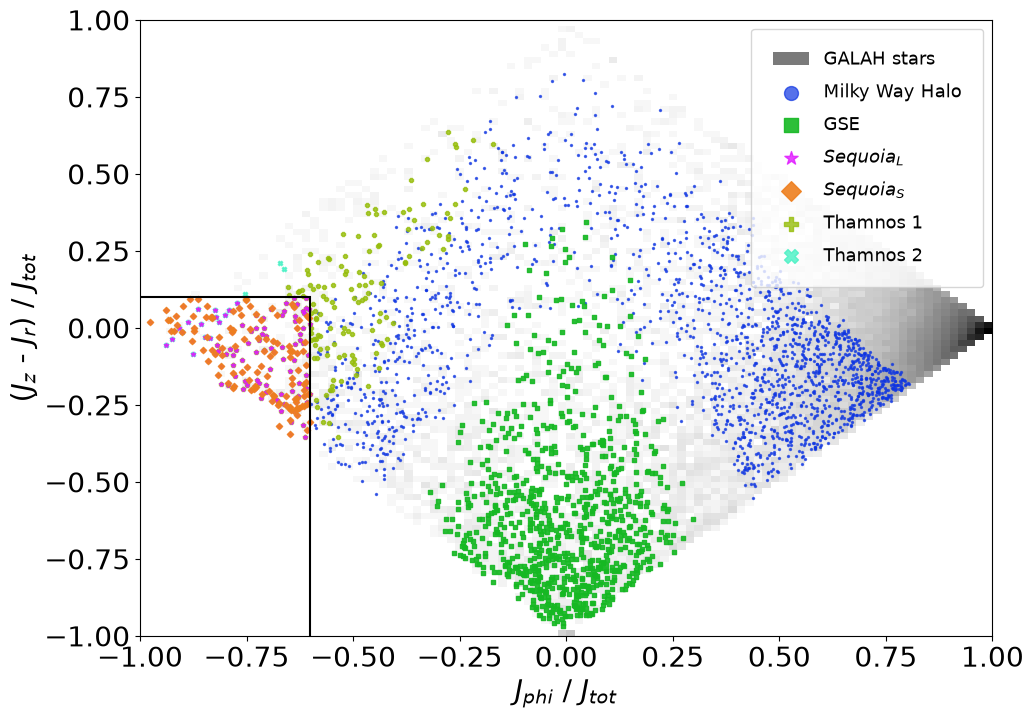

In [148]:
plt.figure(figsize=(11,8))
x_range = (-1, 1)
y_range = (-1, 1)
plt.xlim(x_range)
plt.ylim(y_range)

galah_Gaia_else_plot = galah_Gaia_else[['jphi', 'jtot', 'jz', 'jr']].dropna()
plt.hist2d(galah_Gaia_else_plot['jphi']/galah_Gaia_else_plot['jtot'], (galah_Gaia_else_plot['jz'] - galah_Gaia_else_plot['jr'])/galah_Gaia_else_plot['jtot'], label = 'All Galah stars', bins=(100), range = ((-1, 1), (-1, 1)), cmap=galah_Gaia_else_cmap, norm=LogNorm())

plt.scatter( galah_Gaia_Halo['jphi']/ galah_Gaia_Halo['jtot'], (galah_Gaia_Halo['jz'] - galah_Gaia_Halo['jr'])/galah_Gaia_Halo['jtot'], label = 'Milky Way Halo', s = 2, c = Halo_C, alpha = 0.7, marker = Halo_shape)
plt.scatter( galah_Kushniruk_Thamnos1['jphi']/ galah_Kushniruk_Thamnos1['jtot'], (galah_Kushniruk_Thamnos1['jz'] - galah_Kushniruk_Thamnos1['jr'])/galah_Kushniruk_Thamnos1['jtot'], label = 'Thamnos 1', c = thamnos_1_C, s = 5, alpha = 0.8, marker = thamnos_1_shape)
plt.scatter( galah_Kushniruk_Thamnos2['jphi']/ galah_Kushniruk_Thamnos2['jtot'], (galah_Kushniruk_Thamnos2['jz'] - galah_Kushniruk_Thamnos2['jr'])/galah_Kushniruk_Thamnos2['jtot'], label = 'Thamnos 2', c = thamnos_2_C, s = 10, alpha = 0.8, marker = thamnos_2_shape)
plt.scatter( galah_Gaia_GSE['jphi']/ galah_Gaia_GSE['jtot'], (galah_Gaia_GSE['jz'] - galah_Gaia_GSE['jr'])/galah_Gaia_GSE['jtot'], label = 'GSE', c = GSE_C, s = 10, alpha  = 0.9, marker = GSE_shape)
plt.scatter( galah_Gaia_Sequoia_p_thamnos['jphi']/ galah_Gaia_Sequoia_p_thamnos['jtot'], (galah_Gaia_Sequoia_p_thamnos['jz'] - galah_Gaia_Sequoia_p_thamnos['jr'])/galah_Gaia_Sequoia_p_thamnos['jtot'], label = r'$Sequoia_L$', c = Sequoia_C_2, s = 10, alpha = 0.8, marker = Sequoia_shape_2)
plt.scatter( galah_Gaia_Sequoia['jphi']/ galah_Gaia_Sequoia['jtot'], (galah_Gaia_Sequoia['jz'] - galah_Gaia_Sequoia['jr'])/galah_Gaia_Sequoia['jtot'], label = r'$Sequoia_S$', c = Sequoia_C, s = 10, alpha = 0.9, marker = Sequoia_shape)
plt.scatter( NGC1851_galah['jphi']/ NGC1851_galah['jtot'], (NGC1851_galah['jz'] - NGC1851_galah['jr'])/NGC1851_galah['jtot'], label = 'NGC 1851', s = 50, alpha = 1.0, c = 'r')
plt.tick_params(axis='x', labelsize = labelsize)
plt.tick_params(axis='y', labelsize = labelsize)

# plt.plot([-0.6,-0.6],[0.1,-1], color='orange', linestyle='solid', alpha=1, linewidth=2, path_effects=[pe.Stroke(linewidth=4.5, foreground='black'), pe.Normal()])
# plt.plot([-1,-0.6],[0.1,0.1], color='orange', linestyle='solid', alpha=1, linewidth=2,path_effects=[pe.Stroke(linewidth=4.5, foreground='black'), pe.Normal()])
# plt.axvline(0, color='k', linestyle='--', alpha=0.5)

sequoia_pathch_corner = (-1-0.1,-1-0.1)
width = -0.6 - -1.0 +0.1
height = 0.1 - -1.0 +0.1
rect = patches.Rectangle(sequoia_pathch_corner, width, height,
                           linewidth=1.5,
                           edgecolor='k',
                           facecolor='none',
                           alpha=1.0)       # transparency
ax = plt.gca()
ax.add_patch(rect)


galah_handle = Patch(
    facecolor=plt.get_cmap(galah_Gaia_else_cmap)(0.6),
    edgecolor='none',
    label='GALAH stars'
)
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(galah_handle)
labels.append('GALAH stars')
order = [
    labels.index('GALAH stars'),
    labels.index('Milky Way Halo'),
    labels.index('GSE'),
    labels.index(r'$Sequoia_L$'),
    labels.index(r'$Sequoia_S$'),
    labels.index('Thamnos 1'),
    labels.index('Thamnos 2')
]

leg = plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    fontsize=13,
    labelspacing=0.8,
    borderpad=1.2,
    loc='upper right',
    bbox_to_anchor=(1, 1),
)

for handle in leg.legend_handles:
    try:
        handle.set_sizes([100])
    except Exception:
        pass

plt.xlabel(r'$J_{phi}$ / $J_{tot}$', fontsize = 20)
plt.ylabel(r'($J_z$ - $J_r$) / $J_{tot}$', fontsize = 20)

filename = "action_space.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')

Text(0, 0.5, '($J_z$ - $J_r$) / $J_{tot}$')

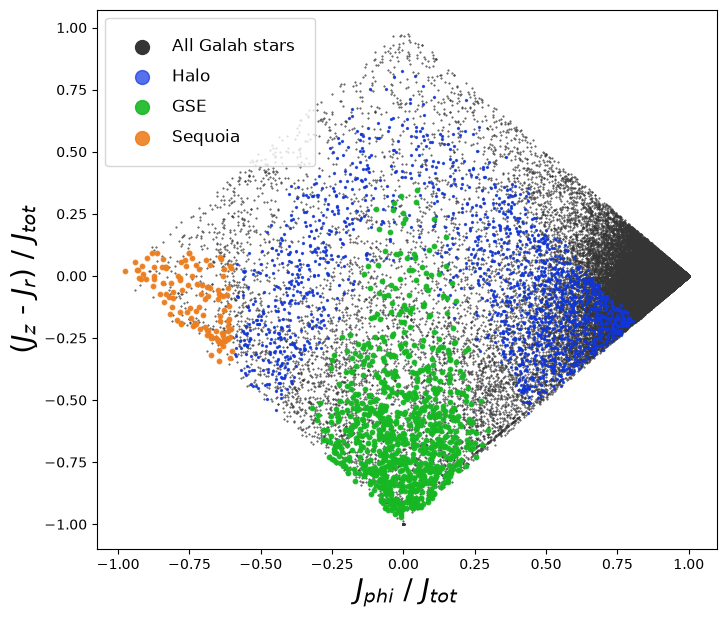

In [149]:
plt.figure(figsize=(8,7))

plt.scatter( galah_Gaia_else['jphi']/ galah_Gaia_else['jtot'], (galah_Gaia_else['jz'] - galah_Gaia_else['jr'])/galah_Gaia_else['jtot'], label = 'All Galah stars', s = 0.2, c = galah_Gaia_else_C, alpha = 1.0)
plt.scatter( galah_Gaia_Halo['jphi']/ galah_Gaia_Halo['jtot'], (galah_Gaia_Halo['jz'] - galah_Gaia_Halo['jr'])/galah_Gaia_Halo['jtot'], label = 'Halo', s = 2, c = Halo_C, alpha = 0.7)
plt.scatter( galah_Gaia_GSE['jphi']/ galah_Gaia_GSE['jtot'], (galah_Gaia_GSE['jz'] - galah_Gaia_GSE['jr'])/galah_Gaia_GSE['jtot'], label = 'GSE', c = GSE_C, s = 10, alpha  = 0.9)
plt.scatter( galah_Gaia_Sequoia['jphi']/ galah_Gaia_Sequoia['jtot'], (galah_Gaia_Sequoia['jz'] - galah_Gaia_Sequoia['jr'])/galah_Gaia_Sequoia['jtot'], label = 'Sequoia', c = Sequoia_C, s = 10, alpha = 0.9)#c = Apogee_Sequoia_new_ratios['mg_mn'], cmap = 'rainbow', s= 3, label = "Apogee_Sequoia")#, vmax  = 0)

# plt.scatter( Sequoia_chem_selected['jphi']/ Sequoia_chem_selected['jtot'], (Sequoia_chem_selected['jz'] - Sequoia_chem_selected['jr'])/Sequoia_chem_selected['jtot'], label = 'chemically selected "Sequoia" stars', c = 'r', s = 10, alpha = 0.9)#c = Apogee_Sequoia_new_ratios['mg_mn'], cmap = 'rainbow', s= 3, label = "Apogee_Sequoia")#, vmax  = 0)

# plt.scatter( galah_Kushniruk_Thamnos1['jphi']/ galah_Kushniruk_Thamnos1['jtot'], (galah_Kushniruk_Thamnos1['jz'] - galah_Kushniruk_Thamnos1['jr'])/galah_Kushniruk_Thamnos1['jtot'], label = 'Thamnos 1', c = 'darkseagreen', s = 10, alpha = 0.9)

leg = plt.legend(fontsize=12, labelspacing=0.8, borderpad=1.2)
for handle in leg.legend_handles:
    handle.set_sizes([100])
plt.xlabel(r'$J_{phi}$ / $J_{tot}$', fontsize = 20)
plt.ylabel(r'($J_z$ - $J_r$) / $J_{tot}$', fontsize = 20)
# plt.colorbar()

[-1.5517331]
Means: [-1.33067166]
Standard deviations: [0.31696595]
Weights: [1.]
Maximum PDF value: 1.2586272152383327


Text(0, 0.5, 'density')

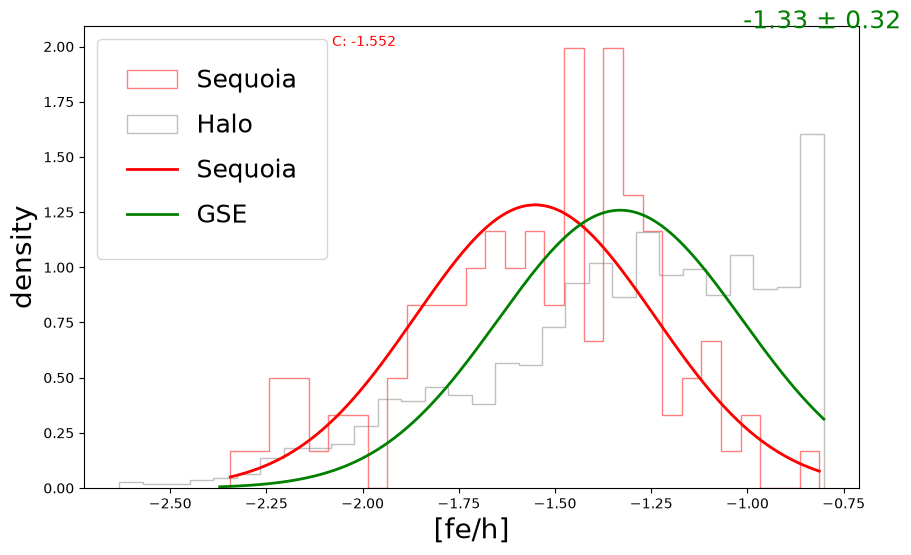

In [150]:
plt.figure(figsize=(10, 6))
elm_ratio = 'fe_h'
n_components = 1
shift_right = 0.32
fontsize = 18

elm_lable = elm_ratio
for i in elm_lable:
    if i == '_':
        elm_lable = elm_lable.replace('_', '/')


plt.hist(galah_Gaia_Sequoia[elm_ratio].dropna(), bins=30, color = 'r', alpha=0.5, label='Sequoia', density=True, histtype='step')
# plt.hist(galah_Gaia_GSE[elm_ratio].dropna(), bins=30, color = 'g', density=True, histtype='step')
plt.hist(galah_Gaia_Halo[elm_ratio].dropna(), bins=30, color = 'grey', alpha=0.5, label='Halo', density=True, histtype='step')
plot_gmm(galah_Gaia_Sequoia[elm_ratio].dropna(), f'Sequoia', n_components = n_components, color='r', maximum_peak=False, plot_compents = True, fontsize = fontsize, shift_right=shift_right, shift_up= 0.91)
plot_gmm(galah_Gaia_GSE[elm_ratio].dropna(), f'GSE', n_components = n_components, color='g', maximum_peak=True, fontsize = fontsize, shift_right=shift_right, shift_up= 0.81)
# plot_gmm(galah_Gaia_Halo[elm_ratio].dropna(), f'Halo', n_components = n_components, color='blue', maximum_peak=True, fontsize = fontsize, shift_right=shift_right, shift_up= 0.71)


# galah_Kushniruk_Thamnos1_mask = (galah_Kushniruk_Thamnos1['fe_h'] <-0.75)
# plt.hist(galah_Kushniruk_Thamnos1[galah_Kushniruk_Thamnos1_mask][elm_ratio].dropna(), bins=30, color = 'darkseagreen', alpha=0.5, label='Thamnos', density=True, histtype='step')
# plot_gmm(galah_Kushniruk_Thamnos1[galah_Kushniruk_Thamnos1_mask][elm_ratio].dropna(), f'Halo', n_components = 3, color='darkseagreen', maximum_peak=True, fontsize = fontsize, shift_right=shift_right, shift_up= 0.61)

leg = plt.legend(fontsize=18, labelspacing=0.8, borderpad=1.2, loc = 'upper left')
# for handle in leg.legend_handles:
    # handle.set_sizes([100])
plt.xlabel(f'[{elm_lable}]', fontsize = 20)
plt.ylabel('density', fontsize = 20)


In [152]:

element_list_partial_small_galah_7 = [ 'fe', 'cu', 'ca', 'mn', 'ti', 'y', 'ni', 'zn', 'v', 'ba','na', 'nd', 'si', 'k', 'sc', 'cr', 'co']
element_list_partial_small_galah_7_2 = ['cu', 'ca', 'mn', 'ti', 'y', 'ni', 'zn', 'v', 'ba','na', 'nd', 'si', 'k', 'sc', 'cr', 'co']
element_list_partial_small_galah_7_3 = ['fe', 'v', 'sc', 'na', 'mg', 'si', 'k', 'ca', 'ti', 'cr', 'mn', 'co', 'ni', 'cu', 'zn', 'y', 'ba', 'nd']
element_list_partial_small_galah_7_4 = ['fe', 'si', 'nd', 'na', 'mg', 'k', 'ca', 'sc', 'ti', 'v', 'cr', 'mn', 'co', 'ni', 'cu', 'zn', 'y', 'ba']
element_list_partial_small_galah_7_5 = [ 'v', 'sc', 'na', 'mg', 'si', 'k', 'ca', 'ti', 'cr', 'mn', 'co', 'ni', 'cu', 'zn', 'y', 'ba', 'nd']  # now I wonder if I could use sm_fe, o_fe, 
element_list_partial_small_galah_10 = ['fe', 'v', 'sc', 'si', 'ca', 'mn', 'na', 'nd']                                                             # and/or la_fe
element_list_partial_small_galah_11 = ['y', 'ba', 'nd', 'eu']                                                                                 # also la and sm would bring me to (50, 45, or 44combined)/65 sequoia stars otherwise
element_list_partial_small_galah_16 =  ["na", "mg", "ca", "ti", "cr" ,"mn", "ni", 'cu', 'y', "ba", "nd"] #This is what I used in my Poster
element_list_partial_small_galah_17 =  ['fe', "na", "mg", "ca", "ti", "cr" ,"mn", "ni", 'cu', 'y', "ba", "nd"]
element_list_partial_small_galah_18 =  ['fe', "na", "mg", 'si', "ca", "ti", "mn", "ni", 'cu', 'y', "ba", "nd"]


ASA_Plots_ratios = ['fe', 'si', 'ca', 'ti', 'mn', 'ni', 'y', 'nd']
S_VS_G_best_elms = ['na', 'mn', 'ti', 'cr']

# element_list = S_VS_G_best_elms
element_list = element_list_partial_small_galah_18


galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia, element_list)

galah_Gaia_new_ratios = galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[0] # this ontains a full catalog from galah but now it includes ratios for Ca, Si, Ti, Ni, Zr, Ce, and Nd relative to eachother: Pradosh did recomend taking out
                                                                 # Si, and Ni whitch I can do by changing "element_list_partial_large" to element_list_partial_small
galah_gaia_new_element_ratio_list = galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[1]     # this just lists the new columns ratios so I can more easily call them
galah_gaia_new_element_ratio_errors_list = galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[2] 

galah_Gaia_GSE_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_GSE, element_list)
galah_Gaia_GSE_new_ratios = galah_Gaia_GSE_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Kushniruk_GSE_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Kushniruk_GSE, element_list)
galah_Gaia_Kushniruk_GSE_new_ratios = galah_Gaia_Kushniruk_GSE_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Sequoia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_Sequoia, element_list)
galah_Gaia_Sequoia_new_ratios = galah_Gaia_Sequoia_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Sequoia_p_Thamnos_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_Sequoia_p_thamnos, element_list)
galah_Gaia_Sequoia_p_Thamnos_new_ratios = galah_Gaia_Sequoia_p_Thamnos_new_ratios_catolog_ratiolist_ratioerrorlist[0]

# galah_Gaia_NGC3201_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(NGC3201_galah, element_list)
# galah_Gaia_NGC3201_new_ratios = galah_Gaia_NGC3201_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_NGC5139_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(NGC5139_galah, element_list)
galah_Gaia_NGC5139_new_ratios = galah_Gaia_NGC5139_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Thamnos1_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Kushniruk_Thamnos1, element_list)
galah_Gaia_Thamnos1_new_ratios = galah_Gaia_Thamnos1_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Thamnos2_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Kushniruk_Thamnos2, element_list)
galah_Gaia_Thamnos2_new_ratios = galah_Gaia_Thamnos2_new_ratios_catolog_ratiolist_ratioerrorlist[0]

# galah_Gaia_NGC1851_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(NGC1851_galah, element_list)
# galah_Gaia_NGC1851_new_ratios = galah_Gaia_NGC1851_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Halo_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_Halo, element_list)
galah_Gaia_Halo_new_ratios = galah_Gaia_Halo_new_ratios_catolog_ratiolist_ratioerrorlist[0]

Halo_Pradosh_galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(Halo_Pradosh_galah_Gaia, element_list)
Halo_Pradosh_galah_Gaia_new_ratios = Halo_Pradosh_galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_else_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_else, element_list)
galah_Gaia_else_new_ratios = galah_Gaia_else_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_raw_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah(galah_Gaia_raw, element_list)
galah_Gaia_raw_new_ratios = galah_Gaia_raw_new_ratios_catolog_ratiolist_ratioerrorlist[0]


'----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------'

# element_list_full_galah_almost = ["n", "o", "na", "mg", "al", "si", "k", "ca", "sc" ,"ti", "v", "cr" ,"mn", "co", "ni", "cu", "zn", "y", "zr", "ba", "la", "ce", "nd", "sm", "eu"]# there is nn_li in galah (nural network Li/Fe) but I dont want to include that right now.
element_list_full_galah_almost = ['fe', 'c', 'n', "o", "na", "mg", "al", "si", "k", "ca", "sc" ,"ti", "v", "cr" ,"mn", "co", "ni", "cu", "zn", 
                                  'rb', 'sr', 
                                  "y", "zr", 
                                  'mo', 'ru',
                                  "ba", "la", "ce", "nd", "sm", "eu"]# there is nn_li in galah (nural network Li/Fe) but I dont want to include that right now.


element_list_nessessary_flags = element_list_full_galah_almost

galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia, element_list_nessessary_flags)
galah_Gaia_new_ratios_nessessary_flags_ratio_list = galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[1]
galah_Gaia_new_ratios_nessessary_flags = galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_else_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia_else, element_list_nessessary_flags)
galah_Gaia_else_new_ratios_nessessary_flags = galah_Gaia_else_new_ratios_catolog_ratiolist_ratioerrorlist[0]


galah_Gaia_Sequoia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia_Sequoia, element_list_nessessary_flags)
galah_Gaia_Sequoia_new_ratios_nessessary_flags = galah_Gaia_Sequoia_new_ratios_catolog_ratiolist_ratioerrorlist[0]
 
galah_Gaia_Sequoia_p_Thamnos_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia_Sequoia_p_thamnos, element_list_nessessary_flags)
galah_Gaia_Sequoia_p_Thamnos_new_ratios_nessessary_flags = galah_Gaia_Sequoia_p_Thamnos_new_ratios_catolog_ratiolist_ratioerrorlist[0]


galah_Gaia_GSE_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia_GSE, element_list_nessessary_flags)
galah_Gaia_GSE_new_ratios_nessessary_flags = galah_Gaia_GSE_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Thamnos_1_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Kushniruk_Thamnos1, element_list_nessessary_flags)
galah_Gaia_Thamnos_1_new_ratios_nessessary_flags = galah_Gaia_Thamnos_1_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_Thamnos_2_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Kushniruk_Thamnos2, element_list_nessessary_flags)
galah_Gaia_Thamnos_2_new_ratios_nessessary_flags = galah_Gaia_Thamnos_2_new_ratios_catolog_ratiolist_ratioerrorlist[0]


galah_Gaia_Halo_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(galah_Gaia_Halo, element_list_nessessary_flags)
galah_Gaia_Halo_new_ratios_nessessary_flags = galah_Gaia_Halo_new_ratios_catolog_ratiolist_ratioerrorlist[0]

Halo_Pradosh_galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(Halo_Pradosh_galah_Gaia, element_list_nessessary_flags)
Halo_Pradosh_galah_Gaia_new_ratios_nessessary_flags = Halo_Pradosh_galah_Gaia_new_ratios_catolog_ratiolist_ratioerrorlist[0]

galah_Gaia_NGC5139_new_ratios_catolog_ratiolist_ratioerrorlist = make_elm_ratio_combinations_galah_only_flag_nessessary_columns(NGC5139_galah, element_list_nessessary_flags)
galah_Gaia_NGC5139_new_ratios_nessessary_flags = galah_Gaia_NGC5139_new_ratios_catolog_ratiolist_ratioerrorlist[0]



/Users/simoncorrera/Desktop/MQ NGC3201 project copy/Jupyter Notebooks/equations_file.py:1343: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_set_flagged[new_ratio_error_label] = np.sqrt((data_set_flagged[err_col_numerator])**2 + (data_set_flagged[err_col_denominator])**2)

/Users/simoncorrera/Desktop/MQ NGC3201 project copy/Jupyter Notebooks/equations_file.py:1342: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data_set_flagged[new_ratio_label] = data_set_flagged[col_name_for_numerator] - data_set_flagged[col_name_for_denomin

In [153]:
print(f'len(galah_Gaia_Sequoia_new_ratios): {len(galah_Gaia_Sequoia_new_ratios)}')
print(f'len(galah_Gaia_Sequoia_p_Thamnos_new_ratios): {len(galah_Gaia_Sequoia_p_Thamnos_new_ratios)}')
print(f'len(galah_Gaia_GSE_new_ratios): {len(galah_Gaia_GSE_new_ratios)}')
print(f'len(galah_Gaia_Halo_new_ratios): {len(galah_Gaia_Halo_new_ratios)}')
print(f'len(galah_Gaia_else_new_ratios): {len(galah_Gaia_new_ratios)}')
print(f'len(galah_Gaia_else_new_ratios): {len(galah_Gaia_else_new_ratios)}')


len(galah_Gaia_Sequoia_new_ratios): 69
len(galah_Gaia_Sequoia_p_Thamnos_new_ratios): 122
len(galah_Gaia_GSE_new_ratios): 557
len(galah_Gaia_Halo_new_ratios): 1256
len(galah_Gaia_else_new_ratios): 6471
len(galah_Gaia_else_new_ratios): 154900


In [154]:
Xs = ['c', 'n', "o", "na", "mg", "al", "si", "k", "ca", "sc" ,"ti", "v", "cr" ,"mn", "co", "ni", "cu", "zn", 
                                  'rb', 'sr', 
                                  "y", "zr", 
                                  'mo', 'ru',
                                  "ba", "la", "ce", "nd", "sm", "eu"]
for X in Xs:
    X_fe = X + '_fe'
    X_H = X + '_h'

    galah_Gaia_new_ratios_nessessary_flags[X_H] = galah_Gaia_new_ratios_nessessary_flags[X_fe] + galah_Gaia_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_Sequoia_new_ratios_nessessary_flags[X_H] = galah_Gaia_Sequoia_new_ratios_nessessary_flags[X_fe] + galah_Gaia_Sequoia_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_Sequoia_p_Thamnos_new_ratios_nessessary_flags[X_H] = galah_Gaia_Sequoia_p_Thamnos_new_ratios_nessessary_flags[X_fe] + galah_Gaia_Sequoia_p_Thamnos_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_GSE_new_ratios_nessessary_flags[X_H] = galah_Gaia_GSE_new_ratios_nessessary_flags[X_fe] + galah_Gaia_GSE_new_ratios_nessessary_flags['fe_h']
    Halo_Pradosh_galah_Gaia_new_ratios_nessessary_flags[X_H] = Halo_Pradosh_galah_Gaia_new_ratios_nessessary_flags[X_fe] + Halo_Pradosh_galah_Gaia_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_Thamnos_1_new_ratios_nessessary_flags[X_H] = galah_Gaia_Thamnos_1_new_ratios_nessessary_flags[X_fe] + galah_Gaia_Thamnos_1_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_Thamnos_2_new_ratios_nessessary_flags[X_H] = galah_Gaia_Thamnos_2_new_ratios_nessessary_flags[X_fe] + galah_Gaia_Thamnos_2_new_ratios_nessessary_flags['fe_h']
    galah_Gaia_NGC5139_new_ratios_nessessary_flags[X_H] = galah_Gaia_NGC5139_new_ratios_nessessary_flags[X_fe] + galah_Gaia_NGC5139_new_ratios_nessessary_flags['fe_h']
    
    galah_Gaia_new_ratios[X_H] = galah_Gaia_new_ratios[X_fe] + galah_Gaia_new_ratios['fe_h']
    galah_Gaia_Sequoia_new_ratios[X_H] = galah_Gaia_Sequoia_new_ratios[X_fe] + galah_Gaia_Sequoia_new_ratios['fe_h']
    galah_Gaia_Sequoia_p_Thamnos_new_ratios[X_H] = galah_Gaia_Sequoia_p_Thamnos_new_ratios[X_fe] + galah_Gaia_Sequoia_p_Thamnos_new_ratios['fe_h']
    galah_Gaia_GSE_new_ratios[X_H] = galah_Gaia_GSE_new_ratios[X_fe] + galah_Gaia_GSE_new_ratios['fe_h']
    Halo_Pradosh_galah_Gaia_new_ratios[X_H] = Halo_Pradosh_galah_Gaia_new_ratios[X_fe] + Halo_Pradosh_galah_Gaia_new_ratios['fe_h']
    galah_Gaia_Thamnos1_new_ratios[X_H] = galah_Gaia_Thamnos1_new_ratios[X_fe] + galah_Gaia_Thamnos1_new_ratios['fe_h']
    galah_Gaia_Thamnos2_new_ratios[X_H] = galah_Gaia_Thamnos2_new_ratios[X_fe] + galah_Gaia_Thamnos2_new_ratios['fe_h']
    galah_Gaia_NGC5139_new_ratios[X_H] = galah_Gaia_NGC5139_new_ratios[X_fe] + galah_Gaia_NGC5139_new_ratios['fe_h']




for X in element_list: 
    cut_off = 0.10
    if X == 'fe':
        continue
    if X in ['y', 'ba', 'la', 'ce', 'nd', 'sm', 'eu']:
        cut_off = 0.12
    # print(X, cut_off)
    X_fe = X + '_fe'
    e_X_fe = 'e_' + X_fe
    galah_Gaia_new_ratios = galah_Gaia_new_ratios[galah_Gaia_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_Sequoia_new_ratios = galah_Gaia_Sequoia_new_ratios[galah_Gaia_Sequoia_new_ratios[e_X_fe] < cut_off]
    Halo_Pradosh_galah_Gaia_new_ratios = Halo_Pradosh_galah_Gaia_new_ratios[Halo_Pradosh_galah_Gaia_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_GSE_new_ratios = galah_Gaia_GSE_new_ratios[galah_Gaia_GSE_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_Halo_new_ratios = galah_Gaia_Halo_new_ratios[galah_Gaia_Halo_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_Thamnos1_new_ratios = galah_Gaia_Thamnos1_new_ratios[galah_Gaia_Thamnos1_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_Thamnos2_new_ratios = galah_Gaia_Thamnos2_new_ratios[galah_Gaia_Thamnos2_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_Sequoia_p_Thamnos_new_ratios = galah_Gaia_Sequoia_p_Thamnos_new_ratios[galah_Gaia_Sequoia_p_Thamnos_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_NGC5139_new_ratios = galah_Gaia_NGC5139_new_ratios[galah_Gaia_NGC5139_new_ratios[e_X_fe] < cut_off]
    galah_Gaia_else_new_ratios = galah_Gaia_else_new_ratios[galah_Gaia_else_new_ratios[e_X_fe] < cut_off]
    print(f'{X}, {cut_off}: {len(galah_Gaia_Sequoia_new_ratios)}')
print(f'Seq_lim: {len(galah_Gaia_Sequoia_new_ratios)}')
print(f'Seq_Tham: {len(galah_Gaia_Sequoia_p_Thamnos_new_ratios)}')
print(f'P_Halo: {len(Halo_Pradosh_galah_Gaia_new_ratios)}')
print(f'GSE: {len(galah_Gaia_GSE_new_ratios)}')
print(f'Halo: {len(galah_Gaia_Halo_new_ratios)}')
print(f'Thamnos1: {len(galah_Gaia_Thamnos1_new_ratios)}')
print(f'Thamnos2: {len(galah_Gaia_Thamnos2_new_ratios)}')
print(f'Else: {len(galah_Gaia_else_new_ratios)}')
    

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2438271853.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  galah_Gaia_new_ratios_nessessary_flags[X_H] = galah_Gaia_new_ratios_nessessary_flags[X_fe] + galah_Gaia_new_ratios_nessessary_flags['fe_h']

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_26629/2438271853.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  galah_Gaia_Sequoia_new_ratios_nessessary_flags[X_H] = galah_Gaia_Sequoia_new_ratios_nessessary_flags[X_fe] + galah_Gaia_Sequoia_new_rat

Halo: mean = -1.3313588363995545
GSE: mean = -1.3306716592344499
Seq_lim: mean = -1.5517330978813564
Seq_Tham: mean = -1.5005086115458937


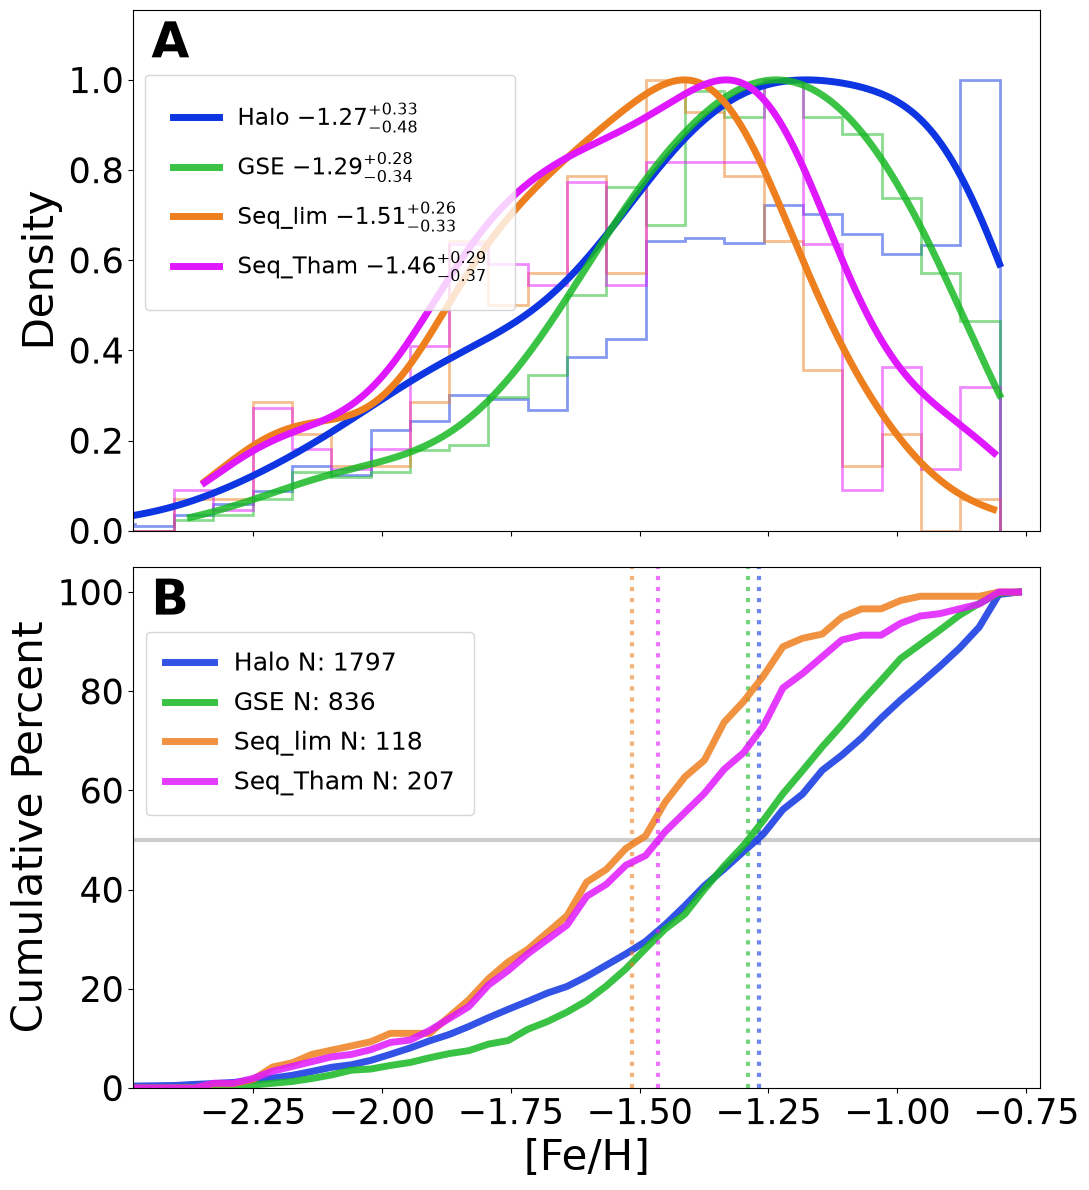

In [155]:
num_bins = 50
percentiles = [16, 50, 84]

elm_ratios = ['fe_h']

# Datasets mapping: name -> (dataframe_with_columns, color)
# datasets = {
#     'Seq': (galah_Gaia_Sequoia_new_ratios, Sequoia_C, 'solid'),
#     # 'Seq_p_Tham': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, Sequoia_C, '--'),
#     'GSE': (galah_Gaia_GSE_new_ratios, GSE_C, 'solid'),
#     'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, Halo_C, 'solid'),
#     # 'Tham1': (galah_Gaia_Thamnos_1_new_ratios, thamnos_1_C, 'solid'),
#     # 'Tham2': (galah_Gaia_Thamnos_2_new_ratios, thamnos_2_C, 'solid'),
# }

datasets = {
    'Halo': (Halo_Pradosh_galah_Gaia_new_ratios_nessessary_flags, Halo_C, 'solid', ':'), #df, color, main_ls, 50%_ls
    'GSE': (galah_Gaia_GSE_new_ratios_nessessary_flags, GSE_C, 'solid', ':'),
    'Seq_lim': (galah_Gaia_Sequoia_new_ratios_nessessary_flags, Sequoia_C, 'solid', ':'),
    'Seq_Tham': (galah_Gaia_Sequoia_p_Thamnos_new_ratios_nessessary_flags, Sequoia_C_2, 'solid', ':'),
    # 'Tham1': (galah_Gaia_Thamnos_1_new_ratios_nessessary_flags, thamnos_1_C, 'solid', ':'),
    # 'Tham2': (galah_Gaia_Thamnos_2_new_ratios_nessessary_flags, thamnos_2_C, 'solid', ':'),
    # 'NGC5139': (galah_Gaia_NGC5139_new_ratios_nessessary_flags, 'orange', 'solid', ':'),
    # 'chem_GSE': (chem_GSE, GSE_C, '--', ':'),
}

# Reference dataset to set the edges/range (use 'Halo' as default)
ref = next(iter(datasets))

for elm_ratio in elm_ratios:
    data, results, edges, min_value, max_value = kde_and_percentiles(datasets, ref, elm_ratio, num_bins = 50, percentiles = [16, 50, 84])


    fig, ax = plt.subplots(2, 1, sharex=True, sharey=False, figsize=(11, 12)) # (rows, colums, share y axis and/or share x axis)
    fontsize = 30
    labelsize = 25

    elm_ratio = elm_ratio
    elm_lable = elm_ratio
    elm_lable_display = ratio_label(elm_ratio)

    n_components = 1
    shift_right = 0.32
    'Gausian Curve for Sequoia'


    # sec_mean = np.mean(galah_Gaia_Sequoia[elm_ratio])
    # one_sig_sec = np.std(galah_Gaia_Sequoia[elm_ratio])
    # pl_1sig_sec = sec_mean + one_sig_sec
    # min_1sig_sec = sec_mean - one_sig_sec
    # plot_gmm(galah_Gaia_Sequoia[elm_ratio].dropna(), f'Sequoia', n_components = n_components, color=Sequoia_C, maximum_peak=True, plot_compents = True, fontsize = fontsize, 
    #         #  shift_right=shift_right, shift_up= 0.91)
    #         shift_right=-0.25, shift_up= 0.2, linewidth_main = 5,
    #         ax = ax[0])
    # ax[0].axvspan(min_1sig_sec, pl_1sig_sec, facecolor=Sequoia_C, alpha=0.2, label = r"$\pm 1\sigma_{\mathrm{Sec}}$")

    # galah_Gaia_Halo_sec_1sig = ((galah_Gaia_Halo[elm_ratio] < pl_1sig_sec) & (galah_Gaia_Halo[elm_ratio] > min_1sig_sec))
    # ax[0].text(sec_mean -0.28, 1.28, f'{len(galah_Gaia_Halo[galah_Gaia_Halo_sec_1sig])} Halo stars in 'r"$\pm 1 \sigma_{\mathrm{Sec}}$", c = Halo_C, fontsize = 13.0)


    'Gausian Curve for GSE'
    # gse_mean = np.mean(galah_Gaia_GSE[elm_ratio])
    # one_sig_gse = np.std(galah_Gaia_GSE[elm_ratio])
    # pl_1sig_gse = gse_mean + one_sig_gse
    # min_1sig_gse = gse_mean - one_sig_gse
    # plot_gmm(galah_Gaia_GSE[elm_ratio].dropna(), f'GSE', n_components = n_components, color=GSE_C, maximum_peak=True, fontsize = fontsize, 
    #         #  shift_right=shift_right, shift_up= 0.81)
    #         shift_right=-0.23, shift_up= 0.4, linewidth_main = 5,
    #         ax = ax[0])
    # ax[0].axvspan(min_1sig_gse, pl_1sig_gse, facecolor=GSE_C, alpha=0.2, label = r"$\pm 1\sigma_{\mathrm{GSE}}$", zorder=0,)

    # galah_Gaia_Halo_gse_1sig = ((galah_Gaia_Halo[elm_ratio] < pl_1sig_gse) & (galah_Gaia_Halo[elm_ratio] > min_1sig_gse))
    # ax[0].text(gse_mean -0.28, 1.55, f'{len(galah_Gaia_Halo[galah_Gaia_Halo_gse_1sig])} Halo stars in 'r"$\pm 1\sigma_{\mathrm{GSE}}$", c = Halo_C, fontsize = 13.0)


    'Gausian Curve for Halo'
    # plot_gmm(galah_Gaia_Halo[elm_ratio].dropna(), f'Halo', n_components = n_components, color='blue', maximum_peak=True, fontsize = fontsize, shift_right=shift_right, shift_up= 0.71)

    ####################################################################
    'Histograms'

    for name, (d, c, ls, ls_2, label, percentiles_label) in data.items():
        # compute shared bin edges from all samples (uses 30 bins)
        all_vals = np.concatenate([t[0].dropna().values for t in data.values()])
        shared_bins = np.linspace(np.nanmin(all_vals), np.nanmax(all_vals), 25)

        counts, bins = np.histogram(d.dropna().values, bins=shared_bins)
        # Normalise so the highest bin = 1
        counts = counts / counts.max() if counts.size and counts.max() > 0 else counts

        ax[0].stairs(
            counts,
            bins,
            color=c,
            ls = ls,
            # label=label,
            linewidth=2,
            alpha = 0.5
        )

    #####################################################################
    'Kernal Density estimates'

    for name, (d, c, ls, ls_2, label, percentiles_label) in data.items():
        x = d.dropna().values
        mean_x = np.mean(x)
        print(f'{name}: mean = {mean_x}')

        # sklearn expects shape (n_samples, n_features)
        x_2d = x.reshape(-1, 1)

        bandwidth_percent = 0.075
        bandwidth_range = np.ptp(x)  # full observed range of the sample
        # print(f'{name}: bandwidth_range', bandwidth_range)
        bandwidth = max(bandwidth_range * bandwidth_percent, 1e-6)
        # print(f'{name}: bandwidth', bandwidth)
        # bandwidth = 0.075
        # print(f'{name}: bandwidth = {bandwidth}')
        kde = KernelDensity(
            kernel='gaussian',
            bandwidth=bandwidth
        )
        
        kde.fit(x_2d)

        x_grid = np.linspace(x.min(), x.max(), 1000).reshape(-1, 1)

        density = np.exp(kde.score_samples(x_grid))
        # normalize so the peak density for this sample is 1
        max_density = density.max() if density.size else 0.0
        if max_density > 0:
            density = density / max_density

        ax[0].plot(
            x_grid[:, 0],
            density,
            color=c,
            ls = ls,
            linewidth=5,
            label= label
        )
        
    ######################################################################
    'labels'
    ax[0].text(0.02, 0.98, 'A', transform=ax[0].transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
    leg = ax[0].legend(fontsize=fontsize/1.8, labelspacing=0.8, borderpad=1.2, frameon=True, loc='center left',
                    bbox_to_anchor=(-0.00, 0.65)
                    )
    # for handle in leg.legend_handles:
        # handle.set_sizes([100])

    peak_height  = max(ax[0].get_ylim())
    ax[0].set_ylim(0, peak_height * 1.1)
    ax[0].tick_params(axis='x', labelsize=labelsize)
    ax[0].tick_params(axis='y', labelsize=labelsize)
    # ax[0].set_xlim(min_value,max_value)


    ax[0].set_ylabel('Density', fontsize = fontsize)

    #########################################################################################

    linewidth = 5
    ax[1].axhline(50, linestyle='solid', linewidth=3, alpha=0.4, c='grey')
    # ax[1].axhline(16, linestyle='solid', linewidth=3, alpha=0.4, c='grey')
    # ax[1].axhline(84, linestyle='solid', linewidth=3, alpha=0.4, c='grey')
    
    #############################################
    x_min_candidates = []
    x_max_candidates = []

    lower_percent = 0.5
    upper_percent = 99

    for name, info in results.items():
        perc = info.get('percents')

        if perc is None or edges is None:
            continue

        perc = np.asarray(perc)
        edges_arr = np.asarray(edges)

        # Find x where cumulative detection is closest to
        # the chosen lower and upper percentages
        valid = np.isfinite(perc) & np.isfinite(edges_arr)

        if not np.any(valid):
            continue

        x_valid = edges_arr[valid]
        p_valid = perc[valid]

        x_lower = x_valid[np.argmin(np.abs(p_valid - lower_percent))]
        x_upper = x_valid[np.argmin(np.abs(p_valid - upper_percent))]

        x_min_candidates.append(x_lower)
        x_max_candidates.append(x_upper)

    # Combine all datasets
    if x_min_candidates and x_max_candidates:
        xmin = min(x_min_candidates)
        xmax = max(x_max_candidates)

        # Add a little padding
        padding = 0.05 * (xmax - xmin)

        ax[1].set_xlim(xmin - padding, xmax + padding)
        ax[0].set_xlim(xmin - padding, xmax + padding)
        
    ##################################################
    # Plot cumulative percent curves from results
    for name, info in results.items():
        pts = info.get('points', {})
        perc = info.get('percents')
        total = info.get('total', 0)
        color = info.get('color', '#000000')
        ls = info.get('ls')
        ls_2 = info.get('ls_2')
        if perc is not None and edges is not None:
            ax[1].plot(edges, perc, color=color, ls = ls, linewidth=linewidth, label=f"{name} N: {total}", alpha=0.85)

        # Vertical lines for percentiles per dataset
        linestyles = {50: ls_2, 
                    #   16: '-.', 
                    #   84: '--'
                    }
        for p, ls_percent in linestyles.items():
            val = pts.get(p, np.nan)
            if not np.isnan(val):
                ax[1].axvline(val, color=color, linestyle=ls_percent, linewidth=3, alpha=0.6)

    # Labels, ticks, legend
    # elm_lable = elm_ratio
    # elm_lable_display = '/'.join([seg.capitalize() for seg in elm_lable.replace('_', '/').split('/')])
    ax[1].set_xlabel(f'{elm_lable_display}', fontsize = fontsize)
    ax[1].set_ylabel('Cumulative Percent', fontsize = fontsize)
    ax[1].tick_params(axis='x', labelsize=labelsize)
    ax[1].tick_params(axis='y', labelsize=labelsize)
    ax[1].text(0.02, 0.98, 'B', transform=ax[1].transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
    leg = ax[1].legend(fontsize=fontsize/1.7, labelspacing=0.6, borderpad=0.8, frameon=True, loc='center left',
                       bbox_to_anchor=(-0.00, 0.70),
                       )
    ax[1].set_ylim(0,105)
    # ax[1].set_xlim(min_value, max_value)

    # ax[0].axvline(-1.2, color=color, linestyle=ls, linewidth=3, alpha=0.6)
    # ax[0].axvline(-1.3, color=color, linestyle=ls, linewidth=3, alpha=0.6)

    plt.tight_layout()
    # plt.savefig('MDF.pdf', bbox_inches='tight', dpi = 300)
    
filename = "MDF.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


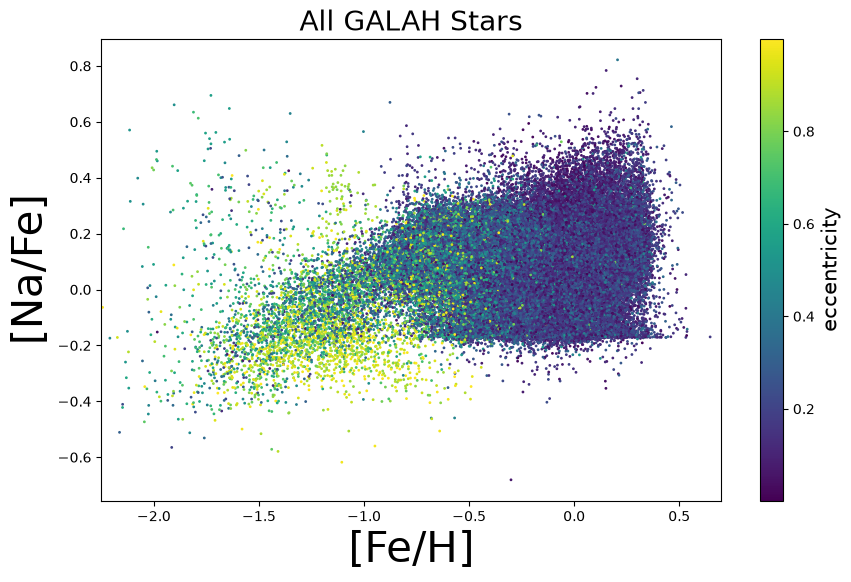

In [156]:
plt.figure(figsize=(10, 6))

elm_ratio1 = 'fe_h'
elm_ratio2 = 'na_fe'
color_col = 'ecc_gaia'

# df = galah_Gaia_else_new_ratios_nessessary_flags
df = galah_Gaia_else_new_ratios

plt.scatter(df[elm_ratio1], df[elm_ratio2], 
            c = df[color_col], #vmin = 0, vmax = 1,
            label = 'All Galah', s = 1, alpha = 1)
# plt.scatter(galah_Gaia_GSE_new_ratios[elm_ratio1], galah_Gaia_GSE_new_ratios[elm_ratio2], color = 'b', label = 'GSE', s = 10)
# plt.scatter(galah_Gaia_Sequoia_new_ratios[elm_ratio1], galah_Gaia_Sequoia_new_ratios[elm_ratio2], color = 'r', label = 'Sequoia', s = 10)


plt.title('All GALAH Stars', fontsize = 20)
elm_lable1 = ratio_label(elm_ratio1)
plt.xlabel(f'{elm_lable1}', fontsize = fontsize)
elm_lable2 = ratio_label(elm_ratio2)
plt.ylabel(f'{elm_lable2}', fontsize = fontsize)

# plt.xlim(-2.75,0.75)
plt.xlim(-2.25,0.7)
cbar = plt.colorbar()
cbar.set_label('eccentricity', fontsize = 15)


filename = "Na_Fe.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


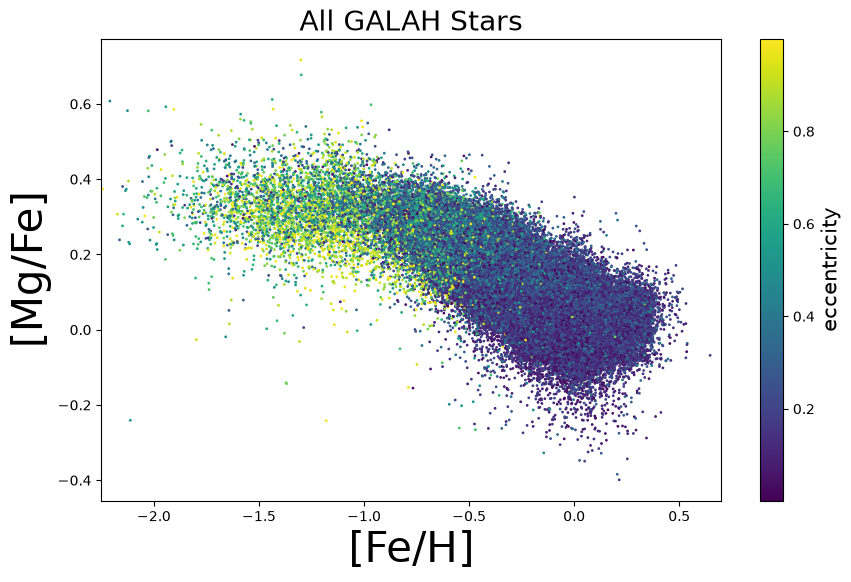

In [157]:
plt.figure(figsize=(10, 6))

elm_ratio1 = 'fe_h'
elm_ratio2 = 'mg_fe'
color_col = 'ecc_gaia'

# df = galah_Gaia_else_new_ratios_nessessary_flags
df = galah_Gaia_else_new_ratios

plt.scatter(df[elm_ratio1], df[elm_ratio2], 
            c = df[color_col], #vmin = 0, vmax = 1,
            label = 'All Galah', s = 1, alpha = 1)
# plt.scatter(galah_Gaia_GSE_new_ratios[elm_ratio1], galah_Gaia_GSE_new_ratios[elm_ratio2], color = 'b', label = 'GSE', s = 10)
# plt.scatter(galah_Gaia_Sequoia_new_ratios[elm_ratio1], galah_Gaia_Sequoia_new_ratios[elm_ratio2], color = 'r', label = 'Sequoia', s = 10)


plt.title('All GALAH Stars', fontsize = 20)
elm_lable1 = ratio_label(elm_ratio1)
plt.xlabel(f'{elm_lable1}', fontsize = fontsize)
elm_lable2 = ratio_label(elm_ratio2)
plt.ylabel(f'{elm_lable2}', fontsize = fontsize)

# plt.xlim(-2.75,0.75)
plt.xlim(-2.25,0.7)
cbar = plt.colorbar()
cbar.set_label('eccentricity', fontsize = 15)


filename = "Mg_fe.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


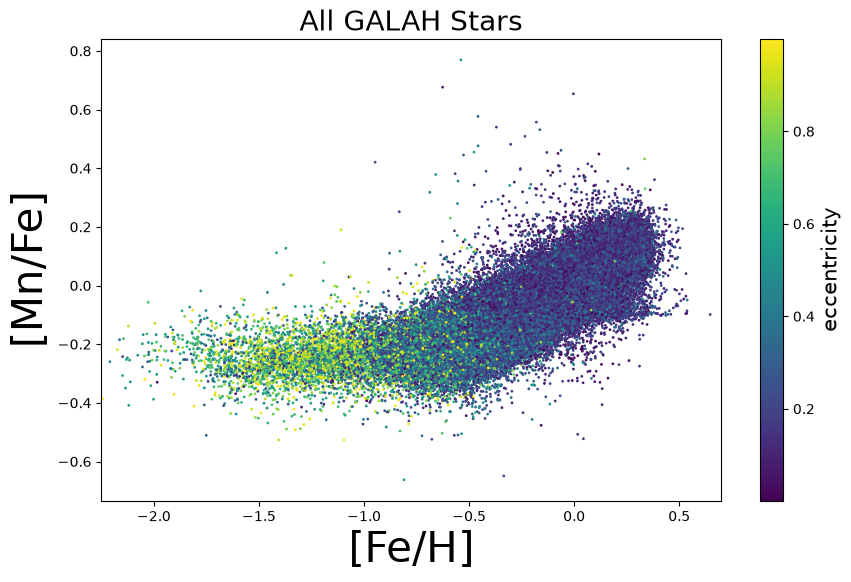

In [158]:
plt.figure(figsize=(10, 6))

elm_ratio1 = 'fe_h'
elm_ratio2 = 'mn_fe'
color_col = 'ecc_gaia'

# df = galah_Gaia_else_new_ratios_nessessary_flags
df = galah_Gaia_else_new_ratios

plt.scatter(df[elm_ratio1], df[elm_ratio2], 
            c = df[color_col], #vmin = 0, vmax = 1,
            label = 'All Galah', s = 1, alpha = 1)
# plt.scatter(galah_Gaia_GSE_new_ratios[elm_ratio1], galah_Gaia_GSE_new_ratios[elm_ratio2], color = 'b', label = 'GSE', s = 10)
# plt.scatter(galah_Gaia_Sequoia_new_ratios[elm_ratio1], galah_Gaia_Sequoia_new_ratios[elm_ratio2], color = 'r', label = 'Sequoia', s = 10)


plt.title('All GALAH Stars', fontsize = 20)
elm_lable1 = ratio_label(elm_ratio1)
plt.xlabel(f'{elm_lable1}', fontsize = fontsize)
elm_lable2 = ratio_label(elm_ratio2)
plt.ylabel(f'{elm_lable2}', fontsize = fontsize)

# plt.xlim(-2.75,0.75)
plt.xlim(-2.25,0.7)
cbar = plt.colorbar()
cbar.set_label('eccentricity', fontsize = 15)

filename = "Mn_fe.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


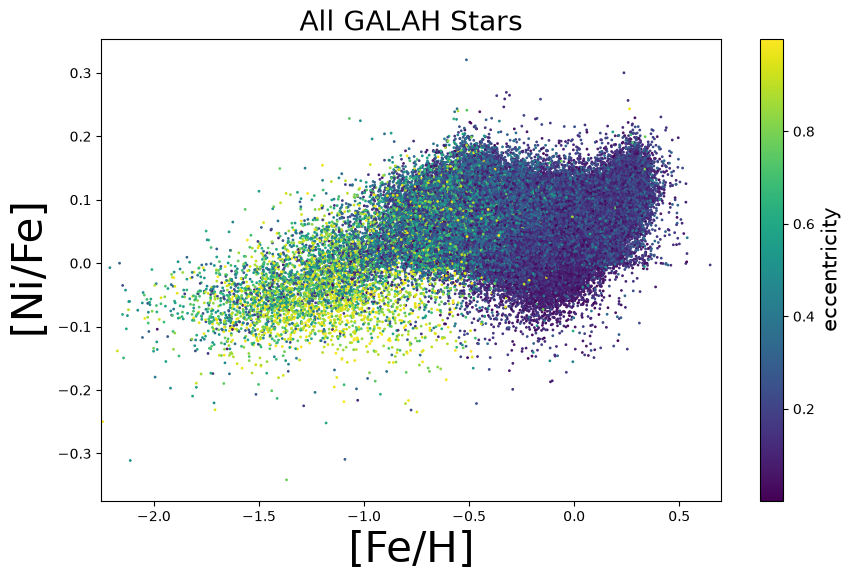

In [159]:
plt.figure(figsize=(10, 6))

elm_ratio1 = 'fe_h'
elm_ratio2 = 'ni_fe'
color_col = 'ecc_gaia'

# df = galah_Gaia_else_new_ratios_nessessary_flags
df = galah_Gaia_else_new_ratios

plt.scatter(df[elm_ratio1], df[elm_ratio2], 
            c = df[color_col], #vmin = 0, vmax = 1,
            label = 'All Galah', s = 1, alpha = 1)
# plt.scatter(galah_Gaia_GSE_new_ratios[elm_ratio1], galah_Gaia_GSE_new_ratios[elm_ratio2], color = 'b', label = 'GSE', s = 10)
# plt.scatter(galah_Gaia_Sequoia_new_ratios[elm_ratio1], galah_Gaia_Sequoia_new_ratios[elm_ratio2], color = 'r', label = 'Sequoia', s = 10)


plt.title('All GALAH Stars', fontsize = 20)
elm_lable1 = ratio_label(elm_ratio1)
plt.xlabel(f'{elm_lable1}', fontsize = fontsize)
elm_lable2 = ratio_label(elm_ratio2)
plt.ylabel(f'{elm_lable2}', fontsize = fontsize)

# plt.xlim(-2.75,0.75)
plt.xlim(-2.25,0.7)
cbar = plt.colorbar()
cbar.set_label('eccentricity', fontsize = 15)


filename = "Ni_fe.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


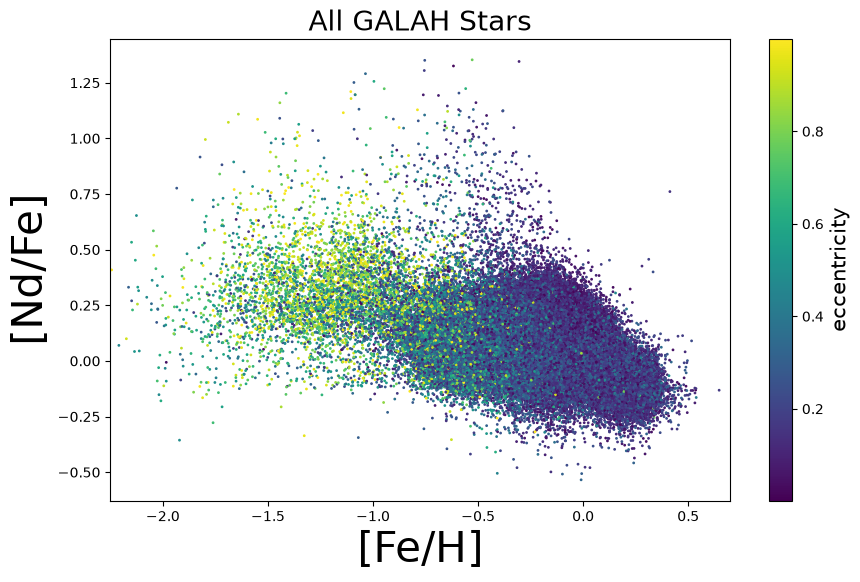

In [160]:
plt.figure(figsize=(10, 6))

elm_ratio1 = 'fe_h'
elm_ratio2 = 'nd_fe'
color_col = 'ecc_gaia'

# df = galah_Gaia_else_new_ratios_nessessary_flags
df = galah_Gaia_else_new_ratios

plt.scatter(df[elm_ratio1], df[elm_ratio2], 
            c = df[color_col], #vmin = 0, vmax = 1,
            label = 'All Galah', s = 1, alpha = 1)
# plt.scatter(galah_Gaia_GSE_new_ratios[elm_ratio1], galah_Gaia_GSE_new_ratios[elm_ratio2], color = 'b', label = 'GSE', s = 10)
# plt.scatter(galah_Gaia_Sequoia_new_ratios[elm_ratio1], galah_Gaia_Sequoia_new_ratios[elm_ratio2], color = 'r', label = 'Sequoia', s = 10)


plt.title('All GALAH Stars', fontsize = 20)
elm_lable1 = ratio_label(elm_ratio1)
plt.xlabel(f'{elm_lable1}', fontsize = fontsize)
elm_lable2 = ratio_label(elm_ratio2)
plt.ylabel(f'{elm_lable2}', fontsize = fontsize)

# plt.xlim(-2.75,0.75)
plt.xlim(-2.25,0.7)
cbar = plt.colorbar()
cbar.set_label('eccentricity', fontsize = 15)


filename = "Nd_fe.pdf"
plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


149 rows for 10.0% of the sample size
Energy test for Seq_lim vs Halo:
expected: 49.666666666666664 / 149 * 4 / 12 or 33.33% of the time
149 rows for 10.0% of the sample size
Energy test for Seq_Tham vs Halo:
expected: 49.666666666666664 / 149 * 4 / 12 or 33.33% of the time
149 rows for 10.0% of the sample size
Energy test for Seq_lim vs GSE:
expected: 49.666666666666664 / 149 * 4 / 12 or 33.33% of the time
149 rows for 10.0% of the sample size
Energy test for Seq_Tham vs GSE:
expected: 49.666666666666664 / 149 * 4 / 12 or 33.33% of the time
149 rows for 10.0% of the sample size
Energy test for GSE vs Halo:
expected: 49.666666666666664 / 149 * 4 / 12 or 33.33% of the time


Element,Seq_lim vs Halo,Seq_Tham vs Halo,Seq_lim vs GSE,Seq_Tham vs GSE,GSE vs Halo
Fe,0.32,0.32,0.46,0.38,0.43
Na,0.56,0.81,0.39,0.45,0.81
Mg,0.26,0.3,0.17,0.21,0.21
Si,0.48,0.68,0.48,0.49,0.22
Ca,0.58,0.32,0.23,0.18,0.21
Ti,0.29,0.31,0.24,0.23,0.23
Mn,0.24,0.37,0.34,0.26,0.4
Ni,0.32,0.35,0.25,0.24,0.24
Cu,0.74,0.34,0.13,0.19,0.2
Y,0.11,0.081,0.49,0.43,0.4


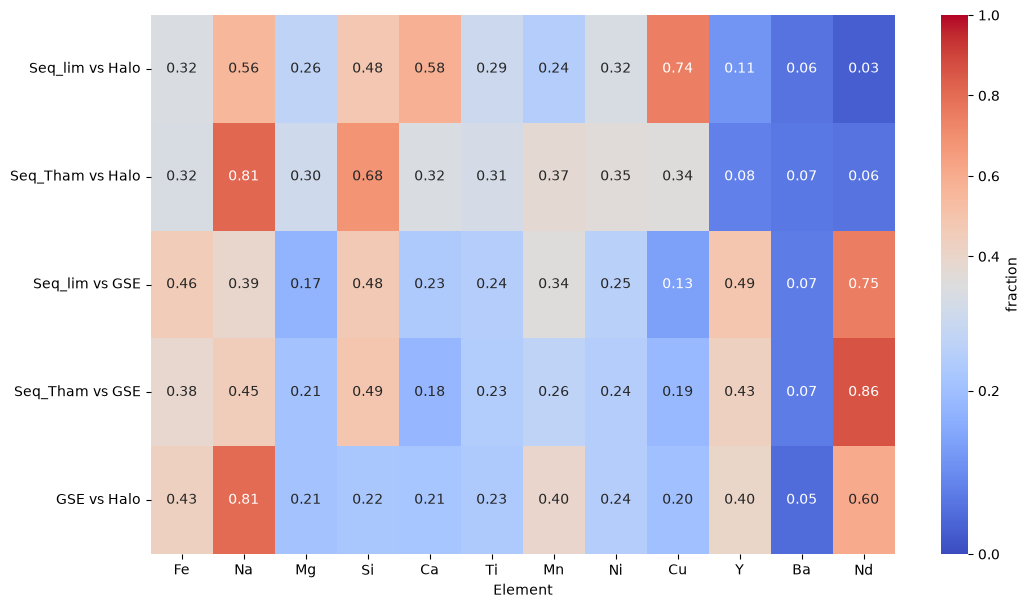

In [161]:
energy_test_dict = {
    # "Seq_lim vs Seq_Tham": Seq_lim_vs_Seq_Tham_energy_test,
    "Seq_lim vs Halo": Seq_lim_vs_Halo_energy_test,
    "Seq_Tham vs Halo": Seq_Tham_vs_Halo_energy_test,
    "Seq_lim vs GSE": Seq_lim_vs_GSE_energy_test,
    "Seq_Tham vs GSE": Seq_Tham_vs_GSE_energy_test,
    "GSE vs Halo": GSE_vs_Halo_energy_test
}

percents = [0.10]
format = 'heat_map_percent' # formats can be: 'percent', 'count', 'bibtext_percent', 'bibtext_count', 'heat_map_count', or 'heat_map_percent'
for percent in percents:
    # n = math.ceil(len(next(iter(energy_test_dict.values()))) * percent)
    # print(f'{n} rows for {percent*100}% of the sample size')

    elm_frequency_table = {}
    for name, energy_test in energy_test_dict.items():
        n = math.ceil(len(energy_test) * percent)
        print(f'{n} rows for {percent*100}% of the sample size')
        energy_test.sort_values(by='p_value', ascending=True, inplace=True)
        print(f"Energy test for {name}:")
        elm_frequency_table[name], element_label_list = energy_tests_best_elements(energy_test_dict[name], name, element_list, n=n, format = format) 
        
    elm_frequency_table = reduce(lambda left, right: pd.merge(left, right, on='Element', how='outer'), elm_frequency_table.values())

    costom_index = []
    # costom_index.append('xi_sq_statistic')
    # costom_index.append('xi_sq_p_value')
    for elm in element_label_list:
        costom_index.append(elm)
    elm_frequency_table = (
        elm_frequency_table
        .set_index("Element")
        .reindex(costom_index)
        .reset_index()
    )

    norm = TwoSlopeNorm(vmin=0, vcenter=0.33, vmax=1)
    # Then pass it to your plot:
    # plt.imshow(data, cmap='coolwarm', norm=norm)
    # or
    # sns.heatmap(data, cmap='coolwarm', norm=norm)
    
    if format == 'heat_map_count' or format == 'heat_map_percent':
        elm_frequency_table.fillna(0, inplace=True)
        plt.figure(figsize=(12, 7))
        sns.heatmap(
            elm_frequency_table.set_index("Element").T,
            annot=True, # 
            fmt=".0f" if format == 'heat_map_count' else ".2f",
            cmap="coolwarm", # YlGnBu, RdBu_r, coolwarm, viridis, plasma, inferno, magma
            norm = norm,
            cbar_kws={"label": "Count" if format == 'heat_map_count' else "fraction"},
        )
            
        filename = "Energy_test_heatmap.pdf"
        plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')
            
    # elm_frequency_table.sort_values(by='Seq_lim vs GSE frequency', ascending=False, inplace=True)
    
    with pd.option_context('display.float_format', lambda x: f'{x:.0f}' if format == 'count' or format == 'heat_map_count' else f'{x:.2g}'):
            display(HTML(elm_frequency_table.to_html(index=False)))
            

In [26]:
for df in [
    galah_Gaia_Sequoia_new_ratios,
    galah_Gaia_GSE_new_ratios,
    galah_Gaia_Halo_new_ratios,
    galah_Gaia_else_new_ratios,
]:
    df['v_si'] = -df['si_v']

/var/folders/k3/63pgq9cd0rvg7fhy2d0q_sj40000gp/T/ipykernel_22579/3330799219.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['v_si'] = -df['si_v']



elm_x: ca_na and elm_y: cu_si


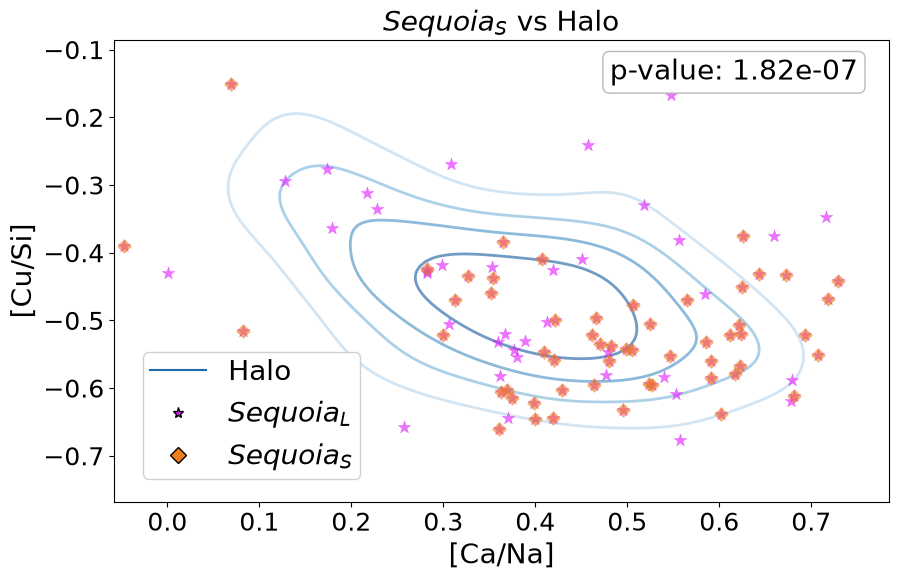

In [214]:
plt.figure(figsize=(10, 6))
fontsize = 20
labelsize = 18

df = Seq_lim_vs_Halo_energy_test
seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = Seq_lim_vs_Halo_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
Seq_lim_VS_Halo = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df[seperate_on].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df[seperate_on].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df[seperate_on].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df[seperate_on].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df[seperate_on].iloc[4], 'E'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'contour', Halo_C, Halo_cmap, Halo_shape, 50),
    # 'GSE': (galah_Gaia_GSE_new_ratios, 'scatter', GSE_C, GSE_cmap, GSE_shape, 15),
    r'$Sequoia_L$': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'scatter', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 90),
    r'$Sequoia_S$': (galah_Gaia_Sequoia_new_ratios, 'scatter', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([Seq_lim_VS_Halo]):
    
    for idx, elm_combos in enumerate(elm_combos):
    
        handles = []
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)
        
        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                plt.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=color, marker = shape, 
                                # edgecolors='k', 
                                linewidths=0.3, zorder=3)
                handles.append(Line2D([0], [0], marker=shape, color='none', markerfacecolor=color, markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.6,
                    # ax=target_ax,
                    zorder=2
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        plt.xlim(x_low - x_pad, x_high + x_pad)
        plt.ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        # target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        plt.xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        plt.ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        plt.tick_params(axis='x', labelsize=labelsize)
        plt.tick_params(axis='y', labelsize=labelsize)
        
        ax = plt.gca()
        plt.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=fontsize,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        ax.legend(
                handles=handles,
                fontsize=fontsize,
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=True,
                fancybox=True,
                borderpad=0.25,
                framealpha=0.9,
                )
        plt.title(r'$Sequoia_S$ vs Halo', fontsize = fontsize)
    filename = "Seq_lim_vs_Halo.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


elm_x: ca_na and elm_y: cu_si
target_ax: Axes(0.125,0.559167;0.775x0.320833)
elm_x: si_na and elm_y: ti_ca
target_ax: Axes(0.125,0.11;0.775x0.320833)


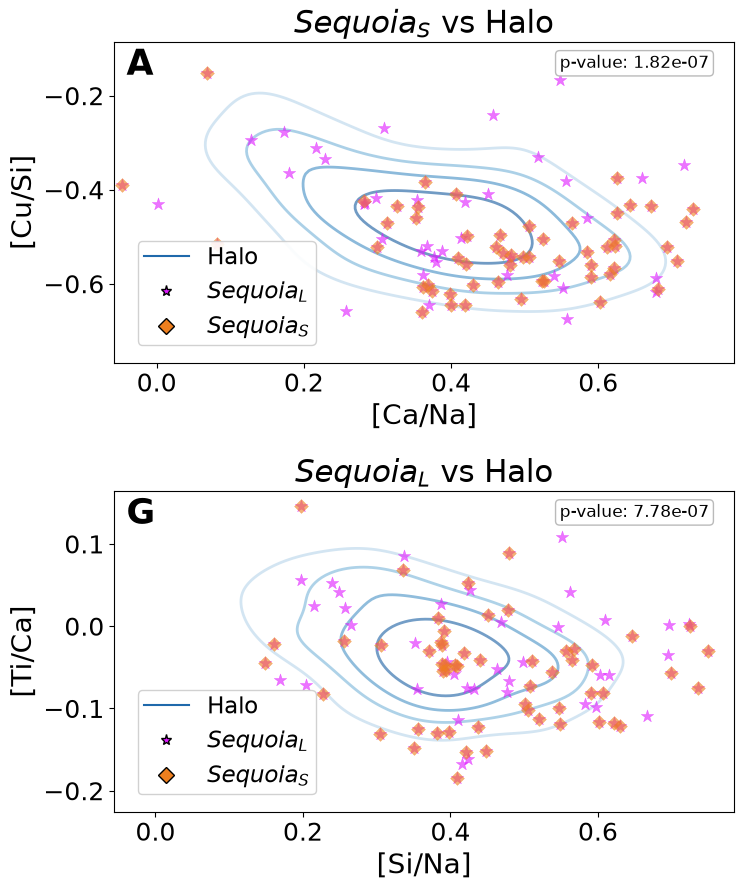

In [223]:
num_rows = 2
num_col = 1
fig, ax = plt.subplots(num_rows, num_col, sharex=False, sharey=False, figsize=(8,10)) # was 20,25
fig.subplots_adjust(hspace=0.40, wspace=0.37) # was 0.3 and 0.25
# plt.tight_layout()
fontsize = 20
labelsize = 18

axes = ax.flatten()
# legend_ax = axes[0]


df = Seq_lim_vs_Halo_energy_test
seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = Seq_lim_vs_Halo_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
Seq_lim_VS_Halo = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df[seperate_on].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df[seperate_on].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df[seperate_on].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df[seperate_on].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df[seperate_on].iloc[4], 'E'],
]

df = Seq_Tham_vs_Halo_energy_test
Seq_Tham_VS_Halo = [
    # [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df[seperate_on].iloc[0], 'F'],
    [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df[seperate_on].iloc[1], 'G'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df[seperate_on].iloc[2], 'H'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df[seperate_on].iloc[3], 'I'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df[seperate_on].iloc[4], 'J'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'contour', Halo_C, Halo_cmap, Halo_shape, 50),
    # 'GSE': (galah_Gaia_GSE_new_ratios, 'scatter', GSE_C, GSE_cmap, GSE_shape, 15),
    r'$Sequoia_L$': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'scatter', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 90),
    r'$Sequoia_S$': (galah_Gaia_Sequoia_new_ratios, 'scatter', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([Seq_lim_VS_Halo, Seq_Tham_VS_Halo]):
    

    for idx, elm_combos in enumerate(elm_combos):
    
        # target_ax = ax[row, idx]  # select the subplot at this row and column
        target_ax = axes[row]  # select the subplot at this row and column
        handles = []

        # if elm_combos[1] == 'cu_ca':
        #     elm_x = elm_combos[1]
        #     eml_y = elm_combos[0]
        # else:
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)

        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                target_ax.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=color, marker = shape, 
                                # edgecolors='k', 
                                linewidths=0.3, zorder=3)
                handles.append(Line2D([0], [0], marker=shape, color='none', markerfacecolor=color, markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.6,
                    ax=target_ax,
                    zorder=2
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        target_ax.set_xlim(x_low - x_pad, x_high + x_pad)
        target_ax.set_ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        target_ax.set_xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        target_ax.set_ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        target_ax.tick_params(axis='x', labelsize=labelsize)
        target_ax.tick_params(axis='y', labelsize=labelsize)
        
        target_ax.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=target_ax.transAxes,
            ha="right",
            va="top",
            fontsize=labelsize/1.5,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        print(f'target_ax: {target_ax}')
        # if target_ax in [ax[0, 2], ax[1, 4]]:            
        #     target_ax.legend(
        #         handles=handles,
        #         fontsize=labelsize/1.75,
        #         loc="lower right",
        #         bbox_to_anchor=(0.98, 0.02),
        #         frameon=True,
        #         fancybox=True,
        #         borderpad=0.25,
        #         framealpha=0.9,
        #         )   
        
        target_ax.legend(
            handles=handles,
            fontsize=labelsize/1.1,
            loc="lower left",
            bbox_to_anchor=(0.02, 0.02),
            frameon=True,
            fancybox=True,
            borderpad=0.25,
            framealpha=0.9,)
                
        if row == 0:
            target_ax.set_title(r'$Sequoia_S$ vs Halo', fontsize=fontsize+2)
        elif row == 1:
            target_ax.set_title(r'$Sequoia_L$ vs Halo', fontsize=fontsize+2)
    
    filename = "Sequoias_vs_Halo.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


elm_x: ca_na and elm_y: cu_si


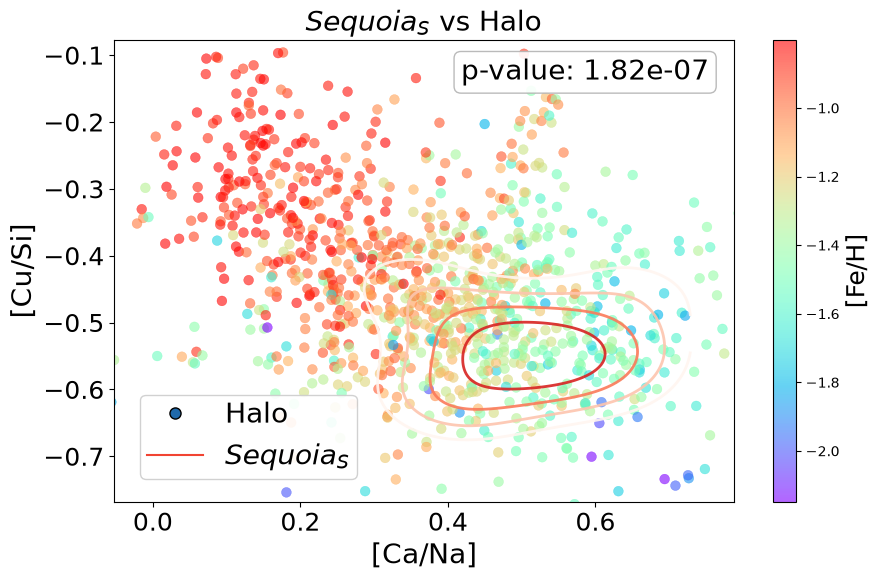

In [240]:
plt.figure(figsize=(10, 6))
fontsize = 20
labelsize = 18

df = Seq_lim_vs_Halo_energy_test
seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = Seq_lim_vs_Halo_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
Seq_lim_VS_Halo = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df[seperate_on].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df[seperate_on].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df[seperate_on].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df[seperate_on].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df[seperate_on].iloc[4], 'E'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'scatter', Halo_C, Halo_cmap, Halo_shape, 50),
    # 'GSE': (galah_Gaia_GSE_new_ratios, 'scatter', GSE_C, GSE_cmap, GSE_shape, 15),
    # r'$Sequoia_L$': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'contour', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 90),
    r'$Sequoia_S$': (galah_Gaia_Sequoia_new_ratios, 'contour', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([Seq_lim_VS_Halo]):
    
    for idx, elm_combos in enumerate(elm_combos):
    
        handles = []
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)
        
        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                if name == 'Halo':
                    scatter_color = df['fe_h']          # array → used for scatter coloring
                    legend_color = plt.get_cmap(cmap)(0.6)  # single colour → used for legend
                    
                    sc = plt.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                                s=size, alpha=0.6, c=scatter_color, cmap = 'rainbow',marker=shape,
                                                linewidths=0.3, zorder=2)
                    cbar = plt.colorbar(sc, orientation='vertical') 
                    cbar.set_label('[Fe/H]', fontsize=labelsize)      # label text + size
                    # cbar.ax.tick_params(labelsize=labelsize)  
                
                else:
                    scatter_color = color
                    legend_color = color
                    plt.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=scatter_color, marker=shape,
                                linewidths=0.3, zorder=2)

                handles.append(Line2D([0], [0], marker=shape, color='none',
                                    markerfacecolor=legend_color,   # ← single colour
                                    markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.9,
                    # ax=target_ax,
                    zorder=3
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        plt.xlim(x_low - x_pad, x_high + x_pad)
        plt.ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        # target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        plt.xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        plt.ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        plt.tick_params(axis='x', labelsize=labelsize)
        plt.tick_params(axis='y', labelsize=labelsize)
        
        ax = plt.gca()
        plt.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=fontsize,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        ax.legend(
                handles=handles,
                fontsize=fontsize,
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=True,
                fancybox=True,
                borderpad=0.25,
                framealpha=0.9,
                )
        plt.title(r'$Sequoia_S$ vs Halo', fontsize = fontsize)
    filename = "Seq_lim_vs_colord_Halo.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


elm_x: si_fe and elm_y: nd_y


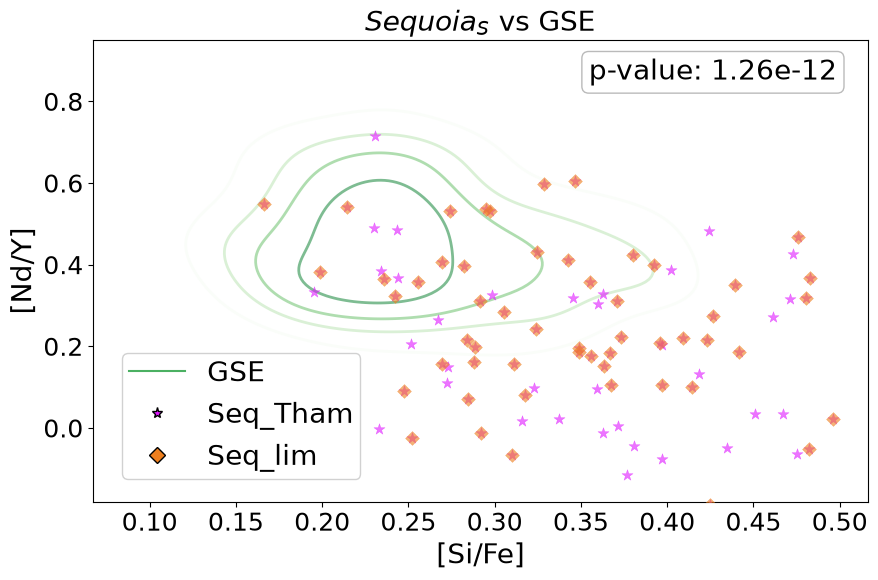

In [207]:
plt.figure(figsize=(10, 6))
fontsize = 20
labelsize = 18

# df = Seq_lim_vs_GSE_energy_test
seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = Seq_lim_vs_GSE_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
Seq_lim_VS_GSE = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df['p_value'].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df['p_value'].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df['p_value'].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df['p_value'].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df['p_value'].iloc[4], 'E'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    # 'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'contour', Halo_C, Halo_cmap, Halo_shape, 50),
    'GSE': (galah_Gaia_GSE_new_ratios, 'contour', GSE_C, GSE_cmap, GSE_shape, 15),
    'Seq_Tham': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'scatter', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 70),
    'Seq_lim': (galah_Gaia_Sequoia_new_ratios, 'scatter', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([Seq_lim_VS_GSE]):
    
    for idx, elm_combos in enumerate(elm_combos):
    
        handles = []
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)
        
        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                plt.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=color, marker = shape, 
                                # edgecolors='k', 
                                linewidths=0.3, zorder=3)
                handles.append(Line2D([0], [0], marker=shape, color='none', markerfacecolor=color, markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.6,
                    # ax=target_ax,
                    zorder=2
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        plt.xlim(x_low - x_pad, x_high + x_pad)
        plt.ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        # target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        plt.xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        plt.ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        plt.tick_params(axis='x', labelsize=labelsize)
        plt.tick_params(axis='y', labelsize=labelsize)
        
        ax = plt.gca()
        plt.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=fontsize,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        ax.legend(
                handles=handles,
                fontsize=fontsize,
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=True,
                fancybox=True,
                borderpad=0.25,
                framealpha=0.9,
                )
        plt.title(r'$Sequoia_S$ vs GSE', fontsize = fontsize)
        
    filename = "Seq_lim_vs_GSE.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


elm_x: si_fe and elm_y: nd_y
target_ax: Axes(0.125,0.559167;0.775x0.320833)
elm_x: si_fe and elm_y: nd_y
target_ax: Axes(0.125,0.11;0.775x0.320833)


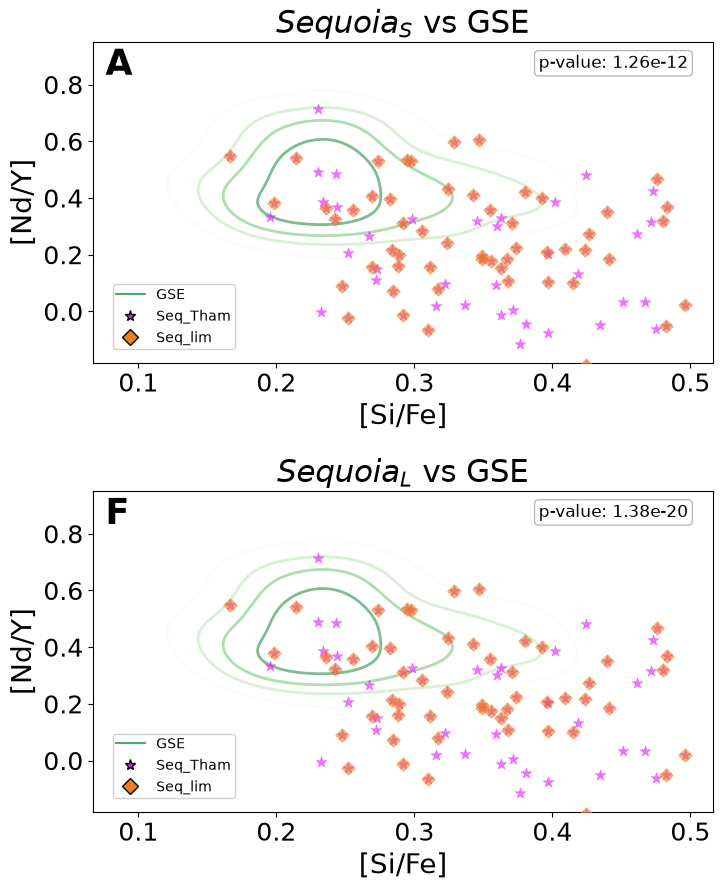

In [209]:
num_rows = 2
num_col = 1
fig, ax = plt.subplots(num_rows, num_col, sharex=False, sharey=False, figsize=(8,10)) # was 20,25
fig.subplots_adjust(hspace=0.40, wspace=0.37) # was 0.3 and 0.25
# plt.tight_layout()
fontsize = 20
labelsize = 18

axes = ax.flatten()
# legend_ax = axes[0]


seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = Seq_lim_vs_GSE_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
Seq_lim_VS_GSE = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df['p_value'].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df['p_value'].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df['p_value'].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df['p_value'].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df['p_value'].iloc[4], 'E'],
]

df = Seq_Tham_vs_GSE_energy_test
Seq_Tham_VS_GSE = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df['p_value'].iloc[0], 'F'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df['p_value'].iloc[1], 'G'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df['p_value'].iloc[2], 'H'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df['p_value'].iloc[3], 'I'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df['p_value'].iloc[4], 'J'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    # 'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'contour', Halo_C, Halo_cmap, Halo_shape, 50),
    'GSE': (galah_Gaia_GSE_new_ratios, 'contour', GSE_C, GSE_cmap, GSE_shape, 15),
    'Seq_Tham': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'scatter', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 70),
    'Seq_lim': (galah_Gaia_Sequoia_new_ratios, 'scatter', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([Seq_lim_VS_GSE, Seq_Tham_VS_GSE]):
    

    for idx, elm_combos in enumerate(elm_combos):
    
        # target_ax = ax[row, idx]  # select the subplot at this row and column
        target_ax = axes[row]  # select the subplot at this row and column
        handles = []

        # if elm_combos[1] == 'cu_ca':
        #     elm_x = elm_combos[1]
        #     eml_y = elm_combos[0]
        # else:
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)

        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                target_ax.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=color, marker = shape, 
                                # edgecolors='k', 
                                linewidths=0.3, zorder=3)
                handles.append(Line2D([0], [0], marker=shape, color='none', markerfacecolor=color, markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.6,
                    ax=target_ax,
                    zorder=2
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        target_ax.set_xlim(x_low - x_pad, x_high + x_pad)
        target_ax.set_ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        target_ax.set_xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        target_ax.set_ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        target_ax.tick_params(axis='x', labelsize=labelsize)
        target_ax.tick_params(axis='y', labelsize=labelsize)
        
        target_ax.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=target_ax.transAxes,
            ha="right",
            va="top",
            fontsize=labelsize/1.5,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        print(f'target_ax: {target_ax}')
        # if target_ax in [ax[0, 2], ax[1, 4]]:            
        #     target_ax.legend(
        #         handles=handles,
        #         fontsize=labelsize/1.75,
        #         loc="lower right",
        #         bbox_to_anchor=(0.98, 0.02),
        #         frameon=True,
        #         fancybox=True,
        #         borderpad=0.25,
        #         framealpha=0.9,
        #         )   
        
        target_ax.legend(
            handles=handles,
            fontsize=labelsize/1.75,
            loc="lower left",
            bbox_to_anchor=(0.02, 0.02),
            frameon=True,
            fancybox=True,
            borderpad=0.25,
            framealpha=0.9,
            )
        
        if row == 0:
            target_ax.set_title(r'$Sequoia_S$ vs GSE', fontsize=fontsize+2)
        elif row == 1:
            target_ax.set_title(r'$Sequoia_L$ vs GSE', fontsize=fontsize+2)
    
    filename = "Sequoias_vs_GSE.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')


elm_x: mn_na and elm_y: nd_y


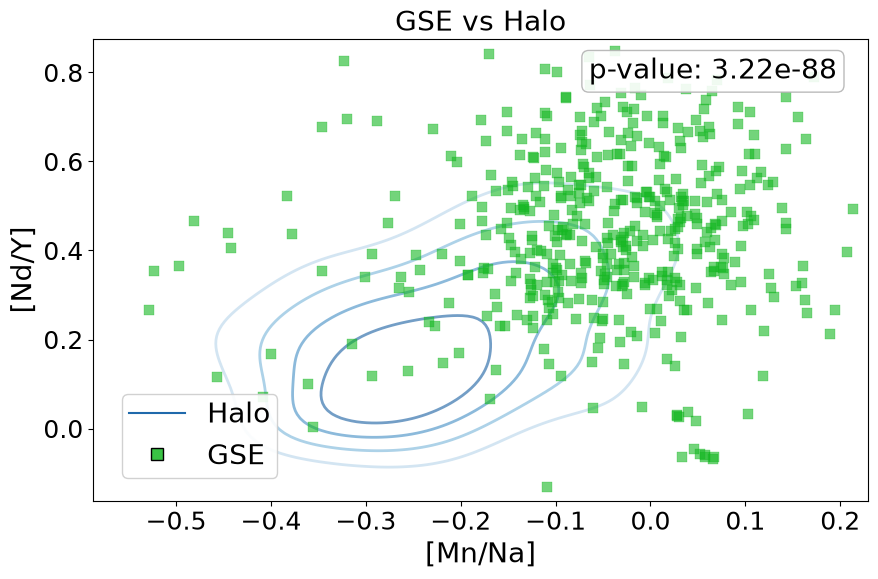

In [211]:
plt.figure(figsize=(10, 6))
fontsize = 20
labelsize = 18

seperate_on = 'p_value' # seperate_on can be 'p_value' or 'statistic
df = GSE_vs_Halo_energy_test.sort_values(by=seperate_on, ascending=True if seperate_on == 'p_value' else False).reset_index(drop=True)
GSE_VS_Halo = [
    [df['ratio 1'].iloc[0], df['ratio 2'].iloc[0], df[seperate_on].iloc[0], 'A'],
    # [df['ratio 1'].iloc[1], df['ratio 2'].iloc[1], df[seperate_on].iloc[1], 'B'],
    # [df['ratio 1'].iloc[2], df['ratio 2'].iloc[2], df[seperate_on].iloc[2], 'C'],
    # [df['ratio 1'].iloc[3], df['ratio 2'].iloc[3], df[seperate_on].iloc[3], 'D'],
    # [df['ratio 1'].iloc[4], df['ratio 2'].iloc[4], df[seperate_on].iloc[4], 'E'],
]

Seq_dict = {
    # 'All Stars': (galah_Gaia_new_ratios, 'scatter', All_C, All_shape, 10),
    'Halo': (Halo_Pradosh_galah_Gaia_new_ratios, 'contour', Halo_C, Halo_cmap, Halo_shape, 50),
    'GSE': (galah_Gaia_GSE_new_ratios, 'scatter', GSE_C, GSE_cmap, GSE_shape, 50),
    # 'Seq_Tham': (galah_Gaia_Sequoia_p_Thamnos_new_ratios, 'scatter', Sequoia_C_2, Sequoia_cmap_2, Sequoia_shape_2, 90),
    # 'Seq_lim': (galah_Gaia_Sequoia_new_ratios, 'scatter', Sequoia_C, Sequoia_cmap, Sequoia_shape, 50),
    # 'Tham2': (galah_Gaia_Thamnos2_new_ratios, 'contour', thamnos_2_C, thamnos_2_cmap, thamnos_2_shape, 90),

}
ref_df = next(iter(Seq_dict.values()))[0]

for row, elm_combos in enumerate([GSE_VS_Halo]):
    
    for idx, elm_combos in enumerate(elm_combos):
    
        handles = []
        elm_x = elm_combos[0]
        elm_y = elm_combos[1]
        p_value = elm_combos[2]
        letter = elm_combos[3]
        print(f'elm_x: {elm_x} and elm_y: {elm_y}')
        elm_lable_x_display = ratio_label(elm_x)
        elm_lable_y_display = ratio_label(elm_y)
        
        x_values = []
        y_values = []

    ###################################    
        
        # Sequoia scatter
        
        for name, (df, plot_type, color, cmap, shape, size) in Seq_dict.items():
            mask_df = df[elm_x].notna() & df[elm_y].notna()
            if plot_type == 'scatter':
                plt.scatter(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y],
                                s=size, alpha=0.6, c=color, marker = shape, 
                                # edgecolors='k', 
                                linewidths=0.3, zorder=3)
                handles.append(Line2D([0], [0], marker=shape, color='none', markerfacecolor=color, markeredgecolor='k', markersize=8, label=name))
            elif plot_type == 'contour':
                sns.kdeplot(
                    x=df.loc[mask_df, elm_x],
                    y=df.loc[mask_df, elm_y],
                    levels=5,
                    cmap=cmap,
                    thresh=0.3,
                    fill=False,
                    linewidths=2,
                    cut=0,
                    alpha=0.6,
                    # ax=target_ax,
                    zorder=2
                )
                handles.append(Line2D([], [], color=plt.get_cmap(cmap)(0.6), linewidth=1.5, label=name))
            elif plot_type == '2d_Hist':
                plt.hist2d(df.loc[mask_df, elm_x], df.loc[mask_df, elm_y], bins=150, cmap=cmap, norm=LogNorm(), zorder=1)
                handles.append(Patch(facecolor=plt.get_cmap(cmap)(0.6), edgecolor='none', label=name))
                
            
            x_values.extend(df.loc[mask_df, elm_x].dropna().values)
            y_values.extend(df.loc[mask_df, elm_y].dropna().values)


        #############################################
        x_values = np.asarray(x_values)
        y_values = np.asarray(y_values)

        # Use percentiles instead of min/max
        x_low, x_high = np.percentile(x_values, [1, 99])
        y_low, y_high = np.percentile(y_values, [1, 99])

        # Add some padding
        x_pad = 0.05 * (x_high - x_low)
        y_pad = 0.05 * (y_high - y_low)
        plt.xlim(x_low - x_pad, x_high + x_pad)
        plt.ylim(y_low - y_pad, y_high + y_pad)
        
        #########################################
        # target_ax.text(0.02, 0.98, f'{letter}', transform=target_ax.transAxes, fontsize=fontsize+5, fontweight='bold', va='top', ha='left')
        plt.xlabel(f'{elm_lable_x_display}', fontsize = fontsize)
        plt.ylabel(f'{elm_lable_y_display}', fontsize = fontsize)
        plt.tick_params(axis='x', labelsize=labelsize)
        plt.tick_params(axis='y', labelsize=labelsize)
        
        ax = plt.gca()
        plt.text(
            0.96, 0.96,
            f"p-value: {p_value:.2e}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=fontsize,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.7", alpha=0.9),
        )

        ax.legend(
                handles=handles,
                fontsize=fontsize,
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=True,
                fancybox=True,
                borderpad=0.25,
                framealpha=0.9,
                )
        plt.title(r'GSE vs Halo', fontsize = fontsize)
    filename = "GSE_vs_Halo.pdf"
    plt.savefig(os.path.join(save_dir, filename), dpi=300, bbox_inches='tight')
